# Потребление домашних хозяйств в регионах России: кластеризация и прогноз

Показатель: фактическое конечное потребление домашних хозяйств на душу населения, рублей в текущих ценах, 2000–2023 годы, источник Росстат. Ряды номинальные, поэтому их рост складывается из роста физического объёма потребления и инфляции. Сравнивать регионы между собой в один год корректно, сравнивать уровни разных лет как уровень жизни нельзя.

Данные и список зависимостей берутся из репозитория проекта на GitHub, поэтому ноутбук работает без ручной загрузки файлов: в клоне репозитория, в Colab и отдельно скачанным. `%pip` ставит пакеты в то же окружение, где работает ядро, в отличие от `!pip`, который может попасть в другой интерпретатор. В `requirements.txt` закреплены версии, на которых ноутбук был выполнен. Если pip заменит уже загруженный numpy или pandas, Colab попросит перезапустить сессию, после перезапуска эту ячейку можно не повторять.

In [1]:
%pip install -q -r https://raw.githubusercontent.com/EgorCOStylev/regional-time-series/main/requirements.txt

In [2]:
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sktime.forecasting.naive import NaiveForecaster

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (13, 5)

REPO_RAW  = 'https://raw.githubusercontent.com/EgorCOStylev/regional-time-series/main'
DATA_FILE = 'data/rsdocs_1491005410458_wide_appendix_2025.csv'
LOCAL     = [p for p in (DATA_FILE, f'../{DATA_FILE}') if os.path.exists(p)]
DATA_PATH = LOCAL[0] if LOCAL else f'{REPO_RAW}/{DATA_FILE}'

## 1. Загрузка и подготовка данных

### 1.1 Чтение файла

Файл читается из папки `data/` репозитория, если ноутбук запущен в его клоне (из корня или из `notebooks/`), иначе скачивается по ссылке из репозитория. Читается без дополнительных параметров, чтобы увидеть, в каком виде лежат данные. В файле десятичная запятая и два вида пропусков (пустая ячейка и символ «…»), поэтому годовые колонки ожидаемо прочитаются как текст.

In [3]:
raw = pd.read_csv(DATA_PATH)
raw.head()

,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,Unnamed: 28
0,Фактическое конечное потребление домашних хозя...,NaN,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"24964,9","33073,8","42325,5",50809,"63177,6","79943,6",...,"296330,1","335157,9","352032,4","378631,5","396539,7","409455,2","482117,7","537330,3","605276,8",NaN
1,Центральный федеральный округ,3.000000e+01,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"37398,9","48743,1","60043,2","71997,2","86784,2","106512,6",...,"371888,6","428461,6","449367,4","483617,8","504322,7","522640,3","622652,4","670468,1","745978,7",NaN
2,Белгородская область,1.400000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"19420,9","22799,1","26386,5",31254,"39422,8","48000,4",...,"252179,1",299984,"321377,9","343531,1",362467,386681,"432635,6",488454,514718,NaN
3,Брянская область,1.500000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"13394,1","18433,1",25521,"31086,7","40350,3","49910,6",...,"241902,5","274857,8","297109,4","323017,1","349656,3","355519,2",406107,"448468,7","489083,4",NaN
4,Владимирская область,1.700000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"13034,5","16869,4","21268,7","27059,7","33793,5","41854,3",...,"220159,8","257385,6","270483,3","290474,2","310050,9","321180,3","360929,3","414359,9","459450,1",NaN


In [4]:
print('Записей:', raw.shape[0], ' колонок:', raw.shape[1])
raw.info()

Записей: 96  колонок: 29
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   region_name     96 non-null     object 
 1   region_code     94 non-null     float64
 2   indicator_name  96 non-null     object 
 3   measure_unit    96 non-null     object 
 4   2000            92 non-null     object 
 5   2001            92 non-null     object 
 6   2002            92 non-null     object 
 7   2003            92 non-null     object 
 8   2004            92 non-null     object 
 9   2005            92 non-null     object 
 10  2006            92 non-null     object 
 11  2007            92 non-null     object 
 12  2008            92 non-null     object 
 13  2009            92 non-null     object 
 14  2010            92 non-null     object 
 15  2011            94 non-null     object 
 16  2012            94 non-null     object 
 17  2013        

Каждая строка соответствует территории, каждый год вынесен в отдельную колонку: это широкий формат. Кроме названия, кода, названия показателя и единицы измерения, в файле есть пустая колонка `Unnamed: 28`: она появилась из-за запятой в конце строки заголовка и данных не содержит. Все 24 годовые колонки прочитались как текст (`object` в pandas 2, `str` в pandas 3). Числовой тип получили только код региона и пустая колонка.

### 1.2 Приведение к числовому формату

Символ «…» заменяется на пропуск, десятичная запятая на точку. В `pd.to_numeric` оставлен режим `errors='raise'`: при `errors='coerce'` любое неожиданное значение молча превратилось бы в пропуск, а здесь оно остановит выполнение и будет замечено.

In [5]:
YEARS = [c for c in raw.columns if c.isdigit()]
df    = raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed')]).copy()

df[YEARS] = (df[YEARS].replace('…', np.nan)
                      .apply(lambda s: pd.to_numeric(s.astype('string').str.replace(',', '.'), errors='raise'))
                      .astype(float))

print('Пропусков в годовых колонках:', int(df[YEARS].isna().sum().sum()))
df[YEARS].dtypes.value_counts()

Пропусков в годовых колонках: 64


,count
float64,24


### 1.3 Проверка названий территорий

Названия используются как ключ при фильтрации и в подписях графиков, поэтому они проверены на смешение алфавитов. В одной строке найдена латинская буква внутри русского слова.

In [6]:
mixed = df['region_name'].str.contains(r'(?=\w*[а-яё])(?=\w*[a-z])\w+', case=False, regex=True)
df.loc[mixed, ['region_name', 'region_code']]

,region_name,region_code
27,Калинингpадская область,NaN


In [7]:
for name in df.loc[mixed, 'region_name']:
    for word in re.findall(r'\w+', name):
        if re.search('[а-яё]', word, re.I) and re.search('[a-z]', word, re.I):
            print(word, [(ch, hex(ord(ch))) for ch in word if ch.isascii()])

Калинингpадская [('p', '0x70')]


В слове «Калинингpадская» буква «р» латинская (U+0070), а код региона у этой строки пустой. Такая строка не совпала бы с правильным названием при поиске или объединении с другими таблицами. Латинские буквы, похожие на кириллические, заменяются на кириллические только в словах, где уже есть кириллица, чтобы не задеть возможные латинские обозначения.

In [8]:
LAT2CYR = str.maketrans('aceopxyABCEHKMOPTXy', 'асеорхуАВСЕНКМОРТХу')

def fix_homoglyphs(text):
    return re.sub(r'\w+',
                  lambda m: m.group().translate(LAT2CYR) if re.search('[а-яё]', m.group(), re.I) else m.group(),
                  text)

df['region_name'] = df['region_name'].map(fix_homoglyphs)
print(df.loc[mixed, 'region_name'].tolist())

['Калининградская область']


### 1.4 Типы записей

Строки делятся на четыре типа: Россия в целом, федеральные округа, агрегаты «без автономного округа» и субъекты. Тип определяется по названию, потому что у Калининградской области код пустой и опираться на код нельзя.

In [9]:
def row_type(name):
    if 'всего' in name:
        return 'РФ'
    if 'федеральный округ' in name:
        return 'федеральный округ'
    if 'без автономн' in name:
        return 'агрегат без АО'
    return 'субъект'

df['row_type'] = df['region_name'].map(row_type)
df['row_type'].value_counts()

,count
row_type,
субъект,85
федеральный округ,8
агрегат без АО,2
РФ,1


### 1.5 Пропуски

Для каждой территории считается число пропущенных лет и первый год с данными.

In [10]:
df['n_missing']  = df[YEARS].isna().sum(axis=1)
df['first_year'] = df[YEARS].notna().idxmax(axis=1)

missing = df.loc[df['n_missing'] > 0, ['region_name', 'row_type', 'n_missing', 'first_year']]
missing.sort_values('n_missing', ascending=False)

,region_name,row_type,n_missing,first_year
41,г. Севастополь,субъект,14,2014
36,Республика Крым,субъект,14,2014
25,Архангельская область без автономного округа,агрегат без АО,11,2011
71,Тюменская область без автономных округов,агрегат без АО,11,2011
48,Чеченская Республика,субъект,5,2005
24,Ненецкий автономный округ,субъект,3,2003
69,Ханты-Мансийский автономный округ – Югра,субъект,3,2003
70,Ямало-Ненецкий автономный округ,субъект,3,2003


In [11]:
print('Пропуски внутри ряда (после первого года с данными):',
      sum(df.loc[i, YEARS[YEARS.index(df.loc[i, 'first_year']):]].isna().sum() for i in df.index))

Пропуски внутри ряда (после первого года с данными): 0


Пропуски есть у восьми территорий, и у всех они стоят в начале ряда, внутри рядов пропусков нет. Республика Крым и г. Севастополь имеют данные с 2014 года (нет 14 лет). Агрегаты «Архангельская область без автономного округа» и «Тюменская область без автономных округов» начинаются в 2011 году (нет 11 лет). Ненецкий, Ханты-Мансийский и Ямало-Ненецкий автономные округа начинаются в 2003 году (нет 3 лет), Чеченская Республика в 2005 году (нет 5 лет).

По условию в анализ входят только субъекты с полным рядом 2000–2023, начальные отрезки не восстанавливаются. Причина в том, что признаки для кластеризации (темп роста, относительное изменение за период, доля лет падения) считаются по всему периоду: у ряда с 2005 года они описывали бы другой отрезок времени, и сравнение с остальными регионами стало бы некорректным. Достроенные экстраполяцией 3–14 лет были бы выдумкой модели, а не наблюдениями.

Исключение автономных округов снимает вопрос о двойном счёте: Тюменская и Архангельская области входят в выборку один раз, целиком, вместе со своими округами. Для Крыма и Севастополя есть ещё одна причина: значения за 2014 год (18,3 и 20,2 тыс. руб. против 185,6 и 164,8 тыс. руб. в 2015 году) похожи на неполный год, а не на годовой показатель.

In [12]:
EXCLUDED = df.loc[(df['row_type'] == 'субъект') & (df['n_missing'] > 0), 'region_name'].tolist()
subj     = df.loc[(df['row_type'] == 'субъект') & (df['n_missing'] == 0)].set_index('region_name')[YEARS]

print('Исключены субъекты с неполным рядом:', EXCLUDED)
print('Исключены агрегаты:', df.loc[df['row_type'] != 'субъект', 'region_name'].tolist())
print('Субъектов в анализе:', len(subj))

Исключены субъекты с неполным рядом: ['Ненецкий автономный округ', 'Республика Крым', 'г. Севастополь', 'Чеченская Республика', 'Ханты-Мансийский автономный округ – Югра', 'Ямало-Ненецкий автономный округ']
Исключены агрегаты: ['Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего', 'Центральный федеральный округ', 'Северо-Западный федеральный округ', 'Архангельская область без автономного округа', 'Южный федеральный округ', 'Северо-Кавказский федеральный округ', 'Приволжский федеральный округ', 'Уральский федеральный округ', 'Тюменская область без автономных округов', 'Сибирский федеральный округ', 'Дальневосточный федеральный округ']
Субъектов в анализе: 79


### 1.6 Проверка на единичные аномалии

Номинальный ряд растёт примерно экспоненциально, поэтому аномалия ищется в логарифмах: для каждого внутреннего года считается отклонение log y_t от среднего log y_{t−1} и log y_{t+1}. Для экспоненциального роста это отклонение близко к нулю независимо от темпа, а для одиночного выброса оно велико.

In [13]:
log_subj = np.log(subj)
spike    = (log_subj - (log_subj.shift(1, axis=1) + log_subj.shift(-1, axis=1)) / 2).abs()

spike.stack().sort_values(ascending=False).head(5).rename('отклонение').to_frame()

отклонение
region_name                                
Красноярский край          2004    0.943155
                           2005    0.497263
                           2003    0.478057
Республика Калмыкия        2003    0.211952
Чукотский автономный округ 2002    0.170073

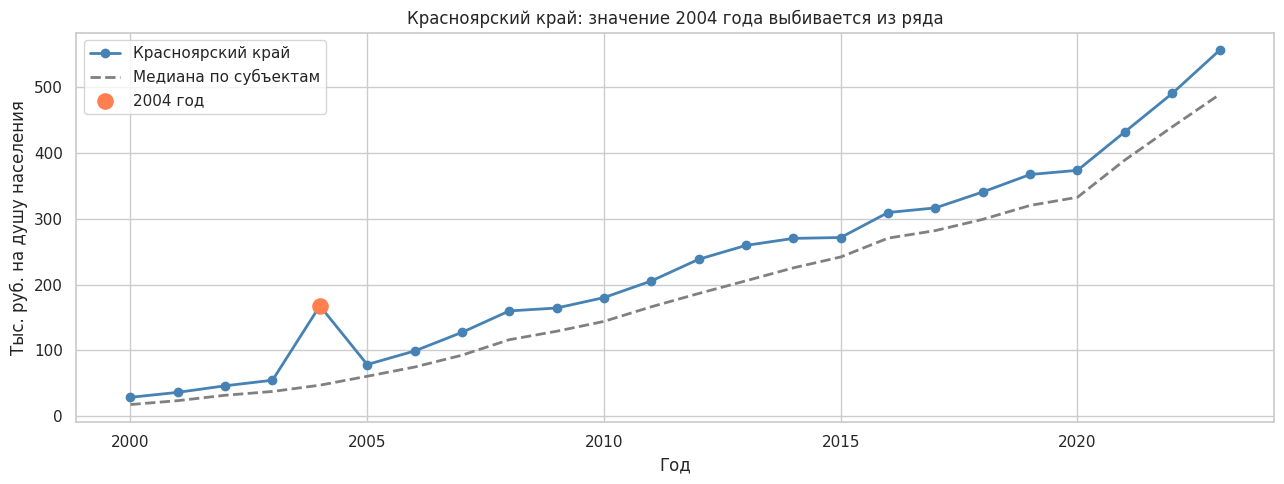

In [14]:
kr = subj.loc['Красноярский край']

fig, ax = plt.subplots()
ax.plot(kr.index.astype(int), kr.values / 1e3, color='steelblue', lw=2, marker='o', label='Красноярский край')
ax.plot(subj.median().index.astype(int), subj.median().values / 1e3, color='gray', lw=2, ls='--', label='Медиана по субъектам')
ax.scatter([2004], [kr['2004'] / 1e3], color='coral', s=120, zorder=3, label='2004 год')
ax.set(title='Красноярский край: значение 2004 года выбивается из ряда', xlabel='Год', ylabel='Тыс. руб. на душу населения')
ax.legend(); plt.tight_layout(); plt.show()

Отклонение Красноярского края в 2004 году равно 0,94 в логарифмах. Соседние 2003 и 2005 годы того же региона получают 0,48 и 0,50 из-за этой же точки, а среди других регионов наибольшее отклонение 0,21 (Калмыкия, 2003 год), в 4,5 раза меньше. Потребление выросло с 54,4 до 167,6 тыс. руб. и на следующий год упало до 78,3 тыс. руб., то есть в 2004 году оно было в 2,1 раза выше уровня 2005 года, хотя ни один регион в 2005 году не снизился. Это похоже на ошибку ввода, а не на экономическое событие. Если оставить точку, она даст максимальное годовое падение в −53% и завысит коэффициент вариации, и регион попадёт в кластер из-за одной ошибочной цифры.

Значение заменяется средним геометрическим соседних лет, это линейная интерполяция в логарифмах, она соответствует экспоненциальному росту ряда. Условие запрещает восстанавливать длинные начальные отрезки, а здесь заменяется одна точка внутри полного ряда. Следующие отклонения (Калмыкия 2003 год 0,21, Чукотский АО 2002 год 0,17, Кемеровская область 2008 год 0,15) втрое-вчетверо меньше и выглядят как реальные ускорения или замедления роста, их не трогаем.

In [15]:
KR_2004_RAW = subj.loc['Красноярский край', '2004']
subj.loc['Красноярский край', '2004'] = np.sqrt(subj.loc['Красноярский край', '2003'] * subj.loc['Красноярский край', '2005'])

print(f'Красноярский край, 2004: {KR_2004_RAW:,.1f} -> {subj.loc["Красноярский край", "2004"]:,.1f} руб.')

Красноярский край, 2004: 167,593.2 -> 65,260.3 руб.


### 1.7 Переход к длинному формату и ряды по регионам

Длинный формат (одна строка на пару «регион, год») удобен для группировок и хранения. Для анализа рядов из него собирается таблица, где индекс это год с частотой `Y`, а каждая колонка это ряд одного региона. Индекс типа `PeriodIndex` с явной частотой нужен statsmodels и sktime: с ним модели строят прогноз на будущие годы без предупреждений о частоте.

In [16]:
long = (subj.reset_index()
            .melt(id_vars='region_name', var_name='year', value_name='consumption')
            .rename(columns={'region_name': 'region'})
            .assign(year=lambda d: d['year'].astype(int))
            .sort_values(['region', 'year'], ignore_index=True))

print('Строк в длинном формате:', len(long), '=', long['region'].nunique(), 'регионов x', long['year'].nunique(), 'лет')
long.head()

Строк в длинном формате: 1896 = 79 регионов x 24 лет


,region,year,consumption
0,Алтайский край,2000,15751.1
1,Алтайский край,2001,21539.7
2,Алтайский край,2002,28855.5
3,Алтайский край,2003,35772.7
4,Алтайский край,2004,44268.9


In [17]:
ts = long.pivot(index='year', columns='region', values='consumption')
ts.index = pd.PeriodIndex(ts.index, freq='Y')

series = {region: ts[region] for region in ts.columns}

print('Размер таблицы рядов:', ts.shape)
series['г. Москва'].head()

Размер таблицы рядов: (24, 79)


,г. Москва
year,
2000,94411.4
2001,119888.7
2002,142603.3
2003,167475.5
2004,189634.3


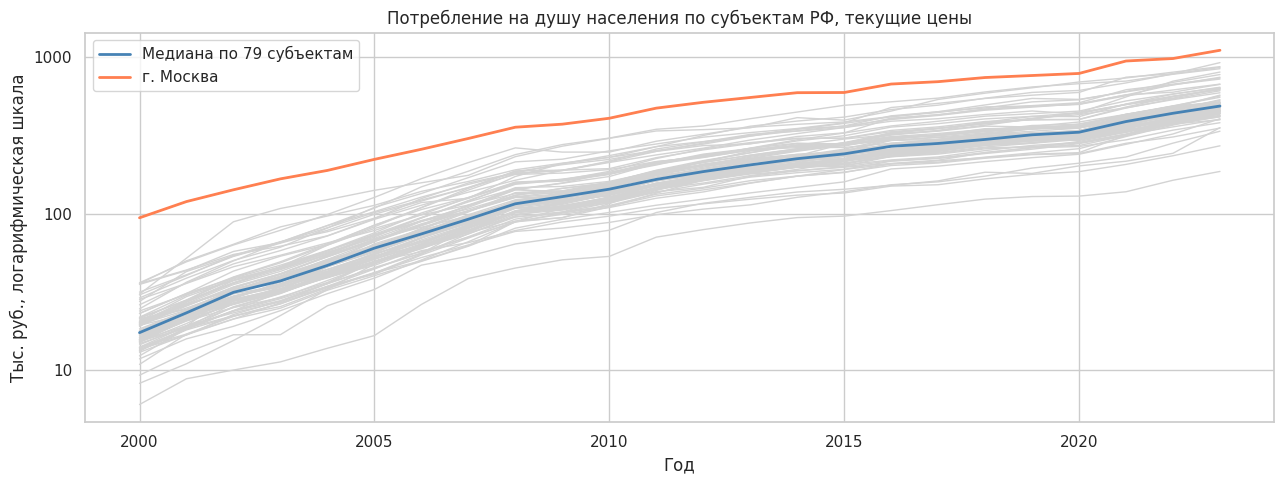

In [18]:
fig, ax = plt.subplots()
for region in ts.columns:
    ax.plot(ts.index.year, ts[region] / 1e3, color='lightgray', lw=1)
ax.plot(ts.index.year, ts.median(axis=1) / 1e3, color='steelblue', lw=2, label='Медиана по 79 субъектам')
ax.plot(ts.index.year, ts['г. Москва'] / 1e3, color='coral', lw=2, label='г. Москва')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set(title='Потребление на душу населения по субъектам РФ, текущие цены', xlabel='Год', ylabel='Тыс. руб., логарифмическая шкала')
ax.legend(); plt.tight_layout(); plt.show()

В логарифмической шкале постоянный темп роста выглядел бы прямой, а здесь кривые круто идут вверх в 2000–2008 годах и выполаживаются к концу периода: номинальный темп роста со временем падает. Медиана за 2000–2023 годы выросла в 28 раз, и большая часть этого роста приходится на инфляцию. Разброс уровней между регионами сохраняется весь период: Москва выше медианы в 2,2–5,4 раза. Темп роста медианы падает с 20–35% в год в 2001–2008 годах до 4–12% в 2013–2020 годах, с провалами в 2009 году (11% после 26%), 2015 году (7%), 2017 году (4%) и 2020 году (4%), а в 2021 году снова поднимается до 17%. Абсолютное снижение потребления редко: в 2009 году оно было у 4 регионов, в 2015 году у 5, в 2020 году у 6, в остальные годы у 0–3 регионов. Именно поэтому для кластеризации абсолютный уровень сам по себе мало что говорит о динамике, и нужны относительные признаки.

## 2. Кластерный анализ регионов

### 2.1 Кандидаты в признаки

Сначала считаются все рекомендованные признаки и несколько дополнительных, затем по корреляциям между ними выбирается набор без дублирования. Темпы роста считаются как относительное изменение к прошлому году, поэтому от масштаба региона и от общего уровня цен они зависят слабо.

Дополнительные признаки:

1. Относительный уровень: среднее за период значение log(y_rt / медиана_t), где медиана берётся по всем 79 регионам в том же году. Это уровень потребления в долях от «типичного» региона того же года, из него убран общий рост цен.
2. Замедление: средний темп роста за 2012–2023 годы минус средний темп за 2001–2011 годы. Делит период на две части почти поровну и показывает, насколько сильно затух рост.
3. Волатильность темпа: стандартное отклонение годовых темпов вокруг их линейного тренда во времени. Обычное стандартное отклонение темпов смешивает два эффекта: плавное замедление (темп падает с 30% до 5%) и рывки. Отклонение от тренда оставляет только рывки.

In [19]:
def show_table(data, title, col_width=None, font=10, height=0.4):
    """Таблица результатов в виде рисунка (идёт в отчёт без перенабора)."""
    fig, ax = plt.subplots(figsize=(13, height * (len(data) + 2)))
    ax.axis('off')
    tab = ax.table(cellText=data.astype(str).values, colLabels=data.columns,
                   rowLabels=data.index,
                   loc='center', cellLoc='center', colWidths=col_width)
    tab.auto_set_font_size(False)
    tab.set_fontsize(font)
    tab.scale(1, 1.4)
    for (r, c), cell in tab.get_celld().items():
        cell.set_edgecolor('black')
        if r == 0:
            cell.set_facecolor('#2c2c2c')
            cell.set_text_props(color='white')
    ax.set_title(title)
    plt.tight_layout(); plt.show()

In [20]:
growth = ts.pct_change().dropna()
growth.index = growth.index.year
t_idx  = np.arange(len(growth))

def detrended_std(s):
    coef = np.polyfit(t_idx, s.values, 1)
    return np.std(s.values - np.polyval(coef, t_idx), ddof=2)

year_median = ts.median(axis=1)

candidates = pd.DataFrame({
    'mean':          ts.mean(),
    'rel_level':     np.log(ts.div(year_median, axis=0)).mean(),
    'cv':            ts.std() / ts.mean(),
    'cagr':          (ts.iloc[-1] / ts.iloc[0]) ** (1 / (len(ts) - 1)) - 1,
    'median_growth': growth.median(),
    'total_change':  ts.iloc[-1] / ts.iloc[0],
    'min_growth':    growth.min(),
    'share_neg':     (growth < 0).mean(),
    'growth_std':    growth.std(),
    'resid_vol':     growth.apply(detrended_std),
    'slowdown':      growth.loc[2012:].mean() - growth.loc[:2011].mean(),
})

candidates.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean,79.0,209967.381,65290.158,75110.612,175928.938,191444.667,231272.877,504230.938
rel_level,79.0,0.044,0.302,-0.981,-0.124,0.002,0.185,1.110
cv,79.0,0.714,0.048,0.582,0.685,0.716,0.749,0.819
cagr,79.0,0.155,0.011,0.113,0.150,0.157,0.161,0.187
median_growth,79.0,0.135,0.016,0.103,0.126,0.134,0.145,0.178
total_change,79.0,28.362,5.954,11.772,25.075,28.676,31.264,51.310
min_growth,79.0,0.014,0.029,-0.094,0.000,0.016,0.038,0.067
share_neg,79.0,0.011,0.020,0.000,0.000,0.000,0.000,0.087
growth_std,79.0,0.103,0.020,0.070,0.090,0.099,0.111,0.183
resid_vol,79.0,0.073,0.019,0.047,0.062,0.070,0.081,0.150


In [21]:
print('Распределение доли лет с падением (в годах из 23):')
print((candidates['share_neg'] * len(growth)).round().astype(int).value_counts().sort_index().to_string())
print('Регионов, у которых минимальный годовой темп положителен:', int((candidates['min_growth'] > 0).sum()), 'из', len(candidates))

Распределение доли лет с падением (в годах из 23):
share_neg
0    60
1    18
2     1
Регионов, у которых минимальный годовой темп положителен: 60 из 79


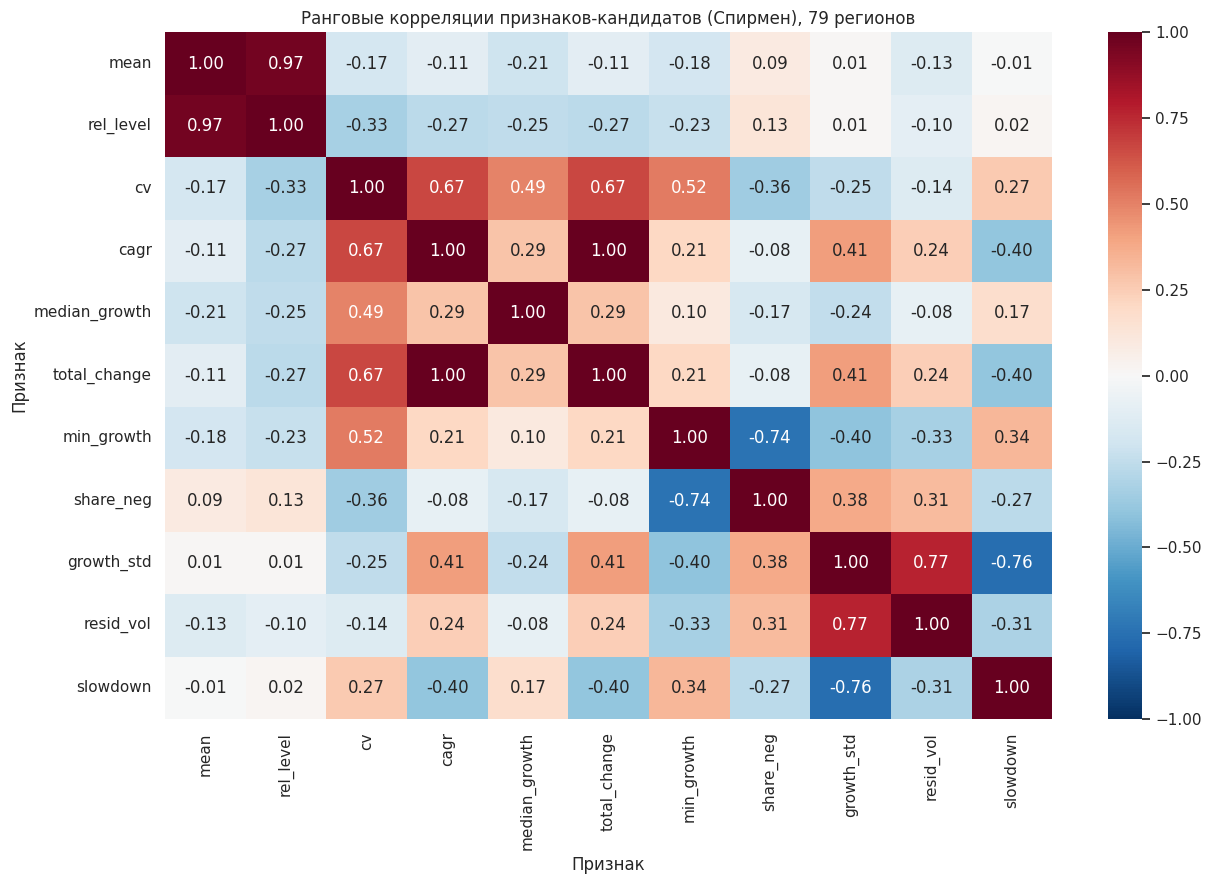

In [22]:
fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(candidates.corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set(title='Ранговые корреляции признаков-кандидатов (Спирмен), 79 регионов', xlabel='Признак', ylabel='Признак')
plt.tight_layout(); plt.show()

Корреляции показывают, какие из рекомендованных признаков дублируют друг друга на этих данных.

Среднее значение и относительный уровень связаны на 0,97: это одно и то же упорядочение регионов. Берётся относительный уровень, потому что среднее номинального ряда почти целиком определяется последними годами, когда цены выше всего, а логарифм отношения к медиане того же года взвешивает все годы одинаково и не даёт Москве оторваться в пять раз от остальных.

Среднегодовой темп (CAGR) и относительное изменение за период связаны на 0,98, потому что CAGR это корень 23-й степени из относительного изменения. Нужен один из них, берётся CAGR как более понятный в процентах.

Коэффициент вариации связан с относительным изменением на 0,67. У ряда, который вырос в 28 раз, стандартное отклонение определяется в первую очередь размахом роста, а не колебаниями, поэтому CV здесь измеряет почти то же, что CAGR. Вместо него волатильность описывает отклонение темпов от их тренда.

Доля лет с падением фактически бинарна: у 60 регионов ноль лет, у 18 один год, у одного два. После стандартизации такой признак делит выборку на «был спад или нет» и тянет кластеры на себя. Ту же информацию непрерывно несёт минимальный годовой темп (у регионов без спада он показывает, насколько близко они подходили к нулю), его связь с долей лет падения −0,74.

Обычное стандартное отклонение темпов связано с замедлением на −0,76: регионы, где рост сильнее затух, имеют и больший разброс темпов. Волатильность вокруг тренда с замедлением связана слабее (−0,31), поэтому в набор входит она.

### 2.2 Итоговый набор признаков и стандартизация

Пять признаков: относительный уровень, CAGR, замедление, волатильность темпа вокруг тренда, минимальный годовой темп. Уровень описывает «где» находится регион, остальные четыре описывают траекторию, поэтому кластеризация определяется в основном динамикой, как требует задание.

Признаки измерены в разных единицах (CAGR около 0,16 с разбросом 0,01, относительный уровень от −1 до 1,1), без стандартизации k-means фактически работал бы по одному относительному уровню, у которого самая большая дисперсия. `StandardScaler` приводит каждый признак к нулевому среднему и единичному отклонению.

In [23]:
FEATURES = ['rel_level', 'cagr', 'slowdown', 'resid_vol', 'min_growth']
FEATURE_NAMES = {
    'rel_level':  'Отн. уровень (log к медиане)',
    'cagr':       'Среднегодовой темп',
    'slowdown':   'Замедление темпа',
    'resid_vol':  'Волатильность темпа',
    'min_growth': 'Мин. годовой темп',
}

X = candidates[FEATURES]
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

print('Максимальная по модулю корреляция между выбранными признаками:',
      round(X.corr(method='spearman').where(~np.eye(len(FEATURES), dtype=bool)).abs().max().max(), 2))
Z.describe().round(2)

Максимальная по модулю корреляция между выбранными признаками: 0.4


,rel_level,cagr,slowdown,resid_vol,min_growth
count,79.00,79.00,79.00,79.00,79.00
mean,-0.00,0.00,0.00,0.00,0.00
std,1.01,1.01,1.01,1.01,1.01
min,-3.41,-3.87,-4.10,-1.44,-3.77
25%,-0.56,-0.47,-0.61,-0.61,-0.49
50%,-0.14,0.15,0.10,-0.19,0.07
75%,0.47,0.55,0.66,0.40,0.82
max,3.55,2.86,2.08,4.16,1.83


In [24]:
outliers = Z.stack()[Z.stack().abs() > 3].round(1).rename('z')
outliers.to_frame()

z
region                                    
Кемеровская область        min_growth -3.8
Республика Дагестан        slowdown   -4.1
Республика Ингушетия       rel_level  -3.4
                           resid_vol   3.1
Республика Калмыкия        resid_vol   3.8
Чукотский автономный округ resid_vol   4.2
г. Москва                  rel_level   3.5
                           cagr       -3.9

У восьми регионов по одному признаку |z| > 3: Москва (очень высокий уровень и самый низкий темп), Ингушетия (самый низкий уровень), Дагестан (самое сильное замедление), Кемеровская область (самое глубокое падение), Калмыкия, Ингушетия и Чукотка (самые резкие рывки темпа). Это не ошибки данных, а настоящие крайние траектории, поэтому они остаются в выборке. Но они влияют на центроиды k-means, это учтено при выборе числа кластеров ниже.

### 2.3 Выбор алгоритма и числа кластеров

Сравниваются k-means и агломеративная кластеризация с методом Уорда при k = 2, 3, 4. У k-means на этой задаче два преимущества. Он даёт центроид, и на этапе 3 типичного представителя можно выбрать как регион, ближайший к центроиду. Признаки непрерывные и стандартизованные, а евклидово расстояние, на котором работает k-means, для них естественно. Уорд минимизирует ту же внутрикластерную дисперсию, но жадно и необратимо (объединённые точки уже не разделяются), поэтому он служит проверкой: если два метода дают близкие разбиения, группы отражают структуру данных, а не случайность инициализации.

У k-means `n_init=50`: алгоритм запускается из 50 случайных начальных центроидов и оставляет лучшее решение, так результат не зависит от одного неудачного старта.

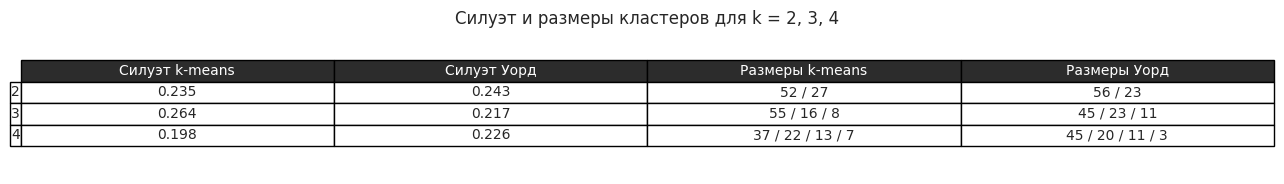

In [25]:
results, labels = [], {}
for k in [2, 3, 4]:
    km   = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Z)
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(Z)
    labels[k] = km.labels_
    results.append({
        'k': k,
        'Силуэт k-means': round(silhouette_score(Z, km.labels_), 3),
        'Силуэт Уорд':    round(silhouette_score(Z, ward.labels_), 3),
        'Размеры k-means': ' / '.join(map(str, sorted(np.bincount(km.labels_), reverse=True))),
        'Размеры Уорд':    ' / '.join(map(str, sorted(np.bincount(ward.labels_), reverse=True))),
    })

sil = pd.DataFrame(results).set_index('k')
show_table(sil, 'Силуэт и размеры кластеров для k = 2, 3, 4')

In [26]:
ward3 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(Z)
seeds = [KMeans(n_clusters=3, n_init=50, random_state=s).fit_predict(Z) for s in range(10)]

print('ARI k-means(k=3) и Уорд(k=3):', round(adjusted_rand_score(labels[3], ward3), 2))
print('Минимальный ARI k-means(k=3) между 10 random_state:', round(min(adjusted_rand_score(seeds[0], s) for s in seeds), 2))

ARI k-means(k=3) и Уорд(k=3): 0.52
Минимальный ARI k-means(k=3) между 10 random_state: 0.87


In [27]:
profiles = {}
for k in [2, 3, 4]:
    profiles[k] = X.assign(cluster=labels[k]).groupby('cluster').mean()
    profiles[k]['n'] = np.bincount(labels[k])

for k in [2, 4]:
    print(f'k = {k}, средние признаков по кластерам:')
    print(profiles[k].round(3).to_string(), end='\n\n')

k = 2, средние признаков по кластерам:
         rel_level   cagr  slowdown  resid_vol  min_growth   n
cluster                                                       
0            0.073  0.158    -0.161      0.087      -0.010  27
1            0.029  0.154    -0.125      0.067       0.027  52

k = 4, средние признаков по кластерам:
         rel_level   cagr  slowdown  resid_vol  min_growth   n
cluster                                                       
0           -0.167  0.163    -0.173      0.116      -0.032   7
1            0.109  0.157    -0.154      0.071      -0.000  22
2           -0.075  0.159    -0.129      0.069       0.035  37
3            0.387  0.140    -0.111      0.067       0.005  13



Силуэт k-means максимален при k = 3 (0,264), при k = 2 он равен 0,235, при k = 4 падает до 0,198. Абсолютные значения невысокие: регионы образуют непрерывное облако без резких границ, и кластеры описывают зоны этого облака, а не изолированные группы. Это свойство данных, а не метода. Уорд при k = 3 даёт силуэт 0,217 и совпадает с k-means частично (ARI 0,52): ядра групп у методов общие, расходятся регионы на границах. Сам k-means устойчив к инициализации (ARI между запусками с разными random_state не ниже 0,87). Лучший силуэт среди всех шести вариантов у k-means при k = 3, поэтому основным выбран он.

Содержательно k = 2 делит регионы на 52 «спокойных» и 27 «неспокойных» (средний минимальный темп +2,7% против −1,0%). Во второй группе вместе оказываются Дагестан и Ингушетия с низким уровнем и быстрым догоняющим ростом и Тюменская область, Татарстан и Сахалин с высоким уровнем: группа объединяет противоположные траектории. При k = 3 из «неспокойных» выделяется ядро из восьми регионов со спадами и рывками, а регионы с высоким уровнем и медленным ровным ростом собираются в отдельную группу вместе с Москвой. При k = 4 средний кластер делится на две части (37 и 22 региона), которые различаются в основном минимальным темпом (+3,5% против 0%) и немного уровнем (−7% и +12% к медиане), темп и замедление у них близки. Такое деление ничего нового о типах траекторий не добавляет, а силуэт падает. По обоим критериям выбрано k = 3.

### 2.4 Описание кластеров

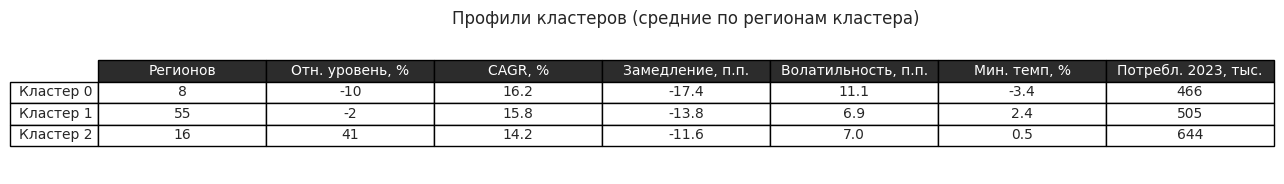

In [28]:
K = 3
km_final = KMeans(n_clusters=K, n_init=50, random_state=42).fit(Z)

# номера кластеров упорядочены по относительному уровню, чтобы описание не зависело от случайной нумерации
order   = X.groupby(km_final.labels_)['rel_level'].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
cluster = pd.Series(km_final.labels_, index=X.index).map(relabel).rename('cluster')
centers = pd.DataFrame(km_final.cluster_centers_, columns=FEATURES).rename(index=relabel).sort_index()

profile = X.assign(cluster=cluster).groupby('cluster').agg(['mean'])
profile.columns = FEATURES
profile['mean_2023'] = ts.iloc[-1].groupby(cluster).mean()
profile['n']         = cluster.value_counts().sort_index()

view = pd.DataFrame({
    'Регионов':            profile['n'],
    'Отн. уровень, %':     ((np.exp(profile['rel_level']) - 1) * 100).round(0).astype(int),
    'CAGR, %':             (profile['cagr'] * 100).round(1),
    'Замедление, п.п.':    (profile['slowdown'] * 100).round(1),
    'Волатильность, п.п.': (profile['resid_vol'] * 100).round(1),
    'Мин. темп, %':        (profile['min_growth'] * 100).round(1),
    'Потребл. 2023, тыс.': (profile['mean_2023'] / 1e3).round(0).astype(int),
})
view.index = [f'Кластер {c}' for c in view.index]
show_table(view, 'Профили кластеров (средние по регионам кластера)')

In [29]:
for c in range(K):
    print(f'Кластер {c} ({(cluster == c).sum()}):', ', '.join(sorted(cluster.index[cluster == c])), end='\n\n')

Кластер 0 (8): Забайкальский край, Кемеровская область, Курганская область, Республика Дагестан, Республика Ингушетия, Республика Калмыкия, Свердловская область, Чукотский автономный округ

Кластер 1 (55): Алтайский край, Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Воронежская область, Еврейская автономная область, Ивановская область, Кабардино-Балкарская Республика, Калужская область, Карачаево-Черкесская Республика, Кировская область, Костромская область, Краснодарский край, Курская область, Ленинградская область, Липецкая область, Московская область, Нижегородская область, Новгородская область, Омская область, Оренбургская область, Орловская область, Пензенская область, Приморский край, Псковская область, Республика Адыгея, Республика Алтай, Республика Башкортостан, Республика Бурятия, Республика Карелия, Республика Марий Эл, Республика Мордовия, Республика Северная Осетия – Алани

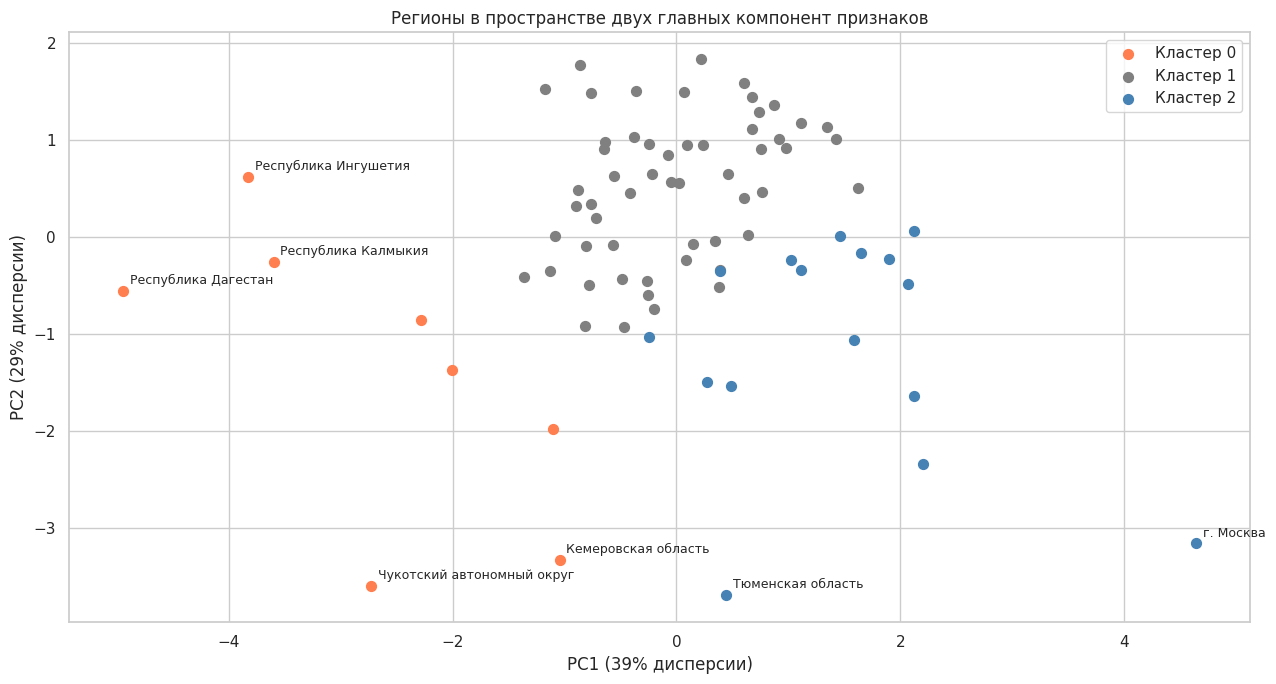

In [30]:
pca  = PCA(n_components=2).fit(Z)
P    = pd.DataFrame(pca.transform(Z), index=Z.index, columns=['pc1', 'pc2'])
cols = {0: 'coral', 1: 'gray', 2: 'steelblue'}

fig, ax = plt.subplots(figsize=(13, 7))
for c in range(K):
    p = P[cluster == c]
    ax.scatter(p['pc1'], p['pc2'], color=cols[c], s=50, label=f'Кластер {c}')
for region in ['г. Москва', 'Республика Ингушетия', 'Чукотский автономный округ', 'Республика Дагестан',
               'Кемеровская область', 'Республика Калмыкия', 'Тюменская область']:
    ax.annotate(region, P.loc[region], xytext=(5, 5), textcoords='offset points', fontsize=9)
ev = pca.explained_variance_ratio_ * 100
ax.set(title='Регионы в пространстве двух главных компонент признаков',
       xlabel=f'PC1 ({ev[0]:.0f}% дисперсии)', ylabel=f'PC2 ({ev[1]:.0f}% дисперсии)')
ax.legend(); plt.tight_layout(); plt.show()

In [31]:
loadings = pd.DataFrame(pca.components_.T, index=[FEATURE_NAMES[f] for f in FEATURES], columns=['PC1', 'PC2']).round(2)
loadings

,PC1,PC2
Отн. уровень (log к медиане),0.32,-0.48
Среднегодовой темп,-0.51,0.43
Замедление темпа,0.57,0.12
Волатильность темпа,-0.50,-0.28
Мин. годовой темп,0.24,0.70


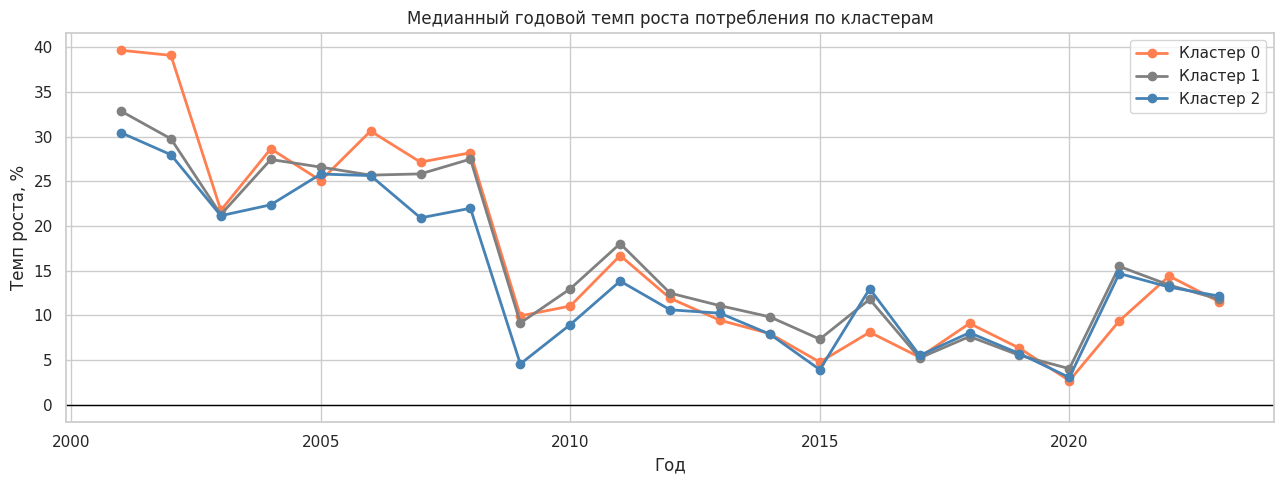

In [32]:
fig, ax = plt.subplots()
for c in range(K):
    g = growth.loc[:, cluster == c].median(axis=1) * 100
    ax.plot(g.index, g.values, color=cols[c], lw=2, marker='o', label=f'Кластер {c}')
ax.axhline(0, color='black', lw=1)
ax.set(title='Медианный годовой темп роста потребления по кластерам', xlabel='Год', ylabel='Темп роста, %')
ax.legend(); plt.tight_layout(); plt.show()

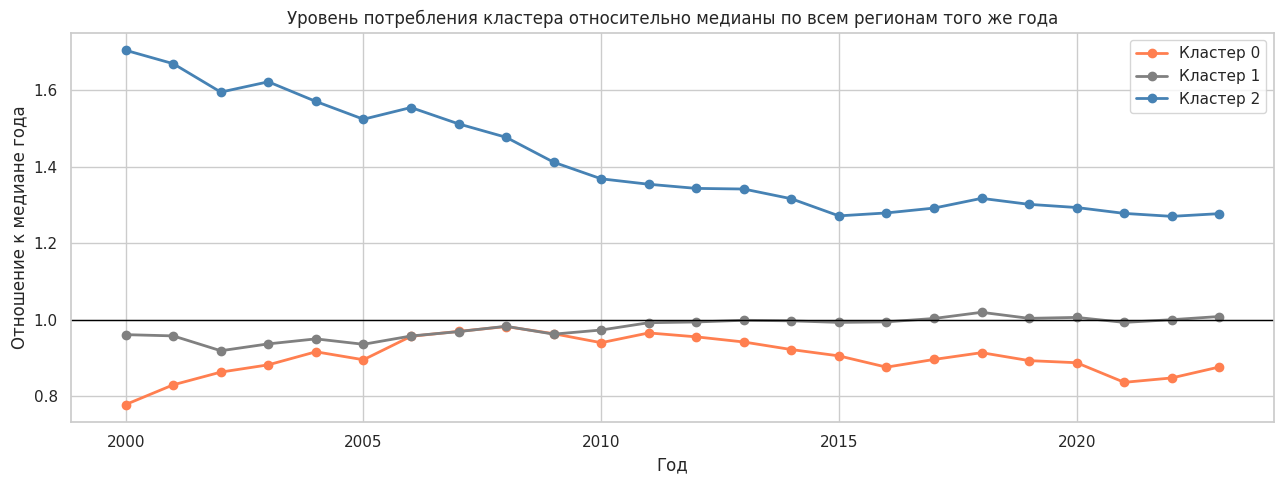

In [33]:
fig, ax = plt.subplots()
for c in range(K):
    r = np.exp(np.log(ts.loc[:, cluster == c].div(year_median, axis=0)).mean(axis=1))
    ax.plot(ts.index.year, r.values, color=cols[c], lw=2, marker='o', label=f'Кластер {c}')
ax.axhline(1, color='black', lw=1)
ax.set(title='Уровень потребления кластера относительно медианы по всем регионам того же года',
       xlabel='Год', ylabel='Отношение к медиане года')
ax.legend(); plt.tight_layout(); plt.show()

Кластер 0, «неустойчивый рост с откатами», 8 регионов: Забайкальский край, Кемеровская, Курганская и Свердловская области, Республики Дагестан, Ингушетия и Калмыкия, Чукотский АО. Средний уровень на 10% ниже медианы, в 2023 году 466 тыс. руб. на человека. Среднегодовой темп самый высокий (16,2%), но и замедление самое сильное (−17,4 п.п.): в 2001–2002 годах медианный рост в группе был около 40% в год, а после 2008 года он чаще ниже, чем у остальных (2016 год: 8,1% против 11,8–13,0%, 2021 год: 9,4% против 14,7–15,5%). Волатильность темпа 11,1 п.п., в 1,6 раза выше, чем у двух других кластеров. Средний минимальный годовой темп −3,4%, и номинальное падение было у 7 из 8 регионов: Кемеровская область −9,4% в 2009 году, Свердловская −4,2% в 2020 году, Дагестан в 2018 и 2020 годах, Курганская область в 2010 году, Чукотка в 2015 году, Калмыкия и Забайкальский край в 2019 году. На графике относительного уровня группа поднялась с 0,78 медианы в 2000 году до 0,98 в 2008 году, затем отстала до 0,84 в 2021 году. Внутри группы два подтипа: южные республики с низким стартовым уровнем и рывками и промышленные регионы Урала и Сибири (уголь, металлургия), чувствительные к сырьевому циклу.

Кластер 1, «ровный рост около медианы», 55 регионов: почти весь Центр, Поволжье, Юг, часть Сибири, а также Санкт-Петербург, Московская область, Татарстан и Краснодарский край. Уровень на 2% ниже медианы, в 2023 году 505 тыс. руб. Темп 15,8%, замедление −13,8 п.п., волатильность 6,9 п.п., средний минимальный темп +2,4%: номинальное падение хотя бы в одном году было только у 8 регионов из 55. Относительный уровень весь период держится у медианы (0,96 в 2000 году, 1,01 в 2023 году), это и есть «типичная» траектория.

Кластер 2, «высокий уровень, медленный рост», 16 регионов: Москва, северные и ресурсные регионы (Тюменская область, Якутия, Коми, Мурманская, Магаданская области, Камчатский край), крупные промышленные (Самарская, Пермский край, Красноярский край, Иркутская, Вологодская области), а также Новосибирская, Томская, Калининградская области и Хабаровский край. Уровень на 41% выше медианы, в 2023 году 644 тыс. руб. Темп самый низкий (14,2%): за 23 года это рост в 21 раз против 29 раз в кластере 1. Замедление самое мягкое (−11,6 п.п.), потому что рост в начале периода был ниже. В 2009 году медианный темп группы упал до 4,5% против 9–10% у остальных: дорогие промышленные и сырьевые регионы сильнее всего задел кризис 2008–2009 годов. Относительный уровень снизился с 1,71 медианы в 2000 году до 1,27 в 2015 году и дальше стоит на месте (1,28 в 2023 году): сближение богатых регионов с остальными шло до 2015 года и прекратилось.

На диаграмме главных компонент (68% дисперсии признаков) PC1 в основном отражает «спокойствие» траектории (положительный вклад замедления, отрицательные вклады темпа и волатильности), PC2 отражает минимальный темп против уровня. Кластер 0 лежит слева, кластер 2 справа внизу, кластер 1 занимает середину и верх. Между кластерами 1 и 2 граница размыта, это согласуется с силуэтом 0,26.

## 3. Выбор регионов для прогнозирования

### 3.1 Расстояние до центроидов

Типичность региона измеряется евклидовым расстоянием до центроида его кластера в стандартизованном пространстве признаков, то есть тем же расстоянием, которое минимизировал k-means. Для каждого кластера показаны три ближайших региона, для кластера 2 также Москва.

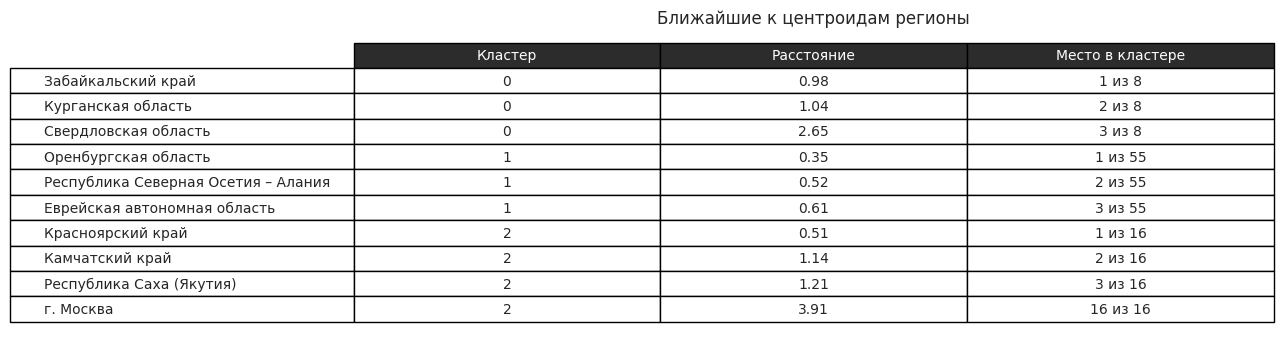

In [34]:
dist = np.sqrt(((Z - centers.loc[cluster].set_index(Z.index)) ** 2).sum(axis=1))

rows = []
for c in range(K):
    d = dist[cluster == c].sort_values()
    for region in list(d.index[:3]) + (['г. Москва'] if c == 2 else []):
        rows.append({'Регион': region, 'Кластер': c, 'Расстояние': round(d[region], 2),
                     'Место в кластере': f'{list(d.index).index(region) + 1} из {len(d)}'})

show_table(pd.DataFrame(rows).set_index('Регион'), 'Ближайшие к центроидам регионы', height=0.3)

In [35]:
print('Центроид кластера 2 в z-оценках:', centers.loc[2].round(2).to_dict())
print('Москва в z-оценках:            ', Z.loc['г. Москва'].round(2).to_dict())

Центроид кластера 2 в z-оценках: {'rel_level': 0.99, 'cagr': -1.26, 'slowdown': 0.81, 'resid_vol': -0.2, 'min_growth': -0.34}
Москва в z-оценках:             {'rel_level': 3.55, 'cagr': -3.87, 'slowdown': 2.03, 'resid_vol': -0.89, 'min_growth': -0.4}


### 3.2 Выбранные регионы

Забайкальский край (кластер 0) ближе всех к центроиду своего кластера (0,98). Кластер 0 неоднородный: южные республики и промышленные регионы Урала и Сибири, и расстояния от центроида до остальных его членов от 1,0 до 3,7. Забайкальский край стоит между этими подтипами и повторяет профиль кластера почти без отклонений: уровень на 5% ниже медианы, темп 16,1%, замедление −17,6 п.п., волатильность 10,6 п.п. (в среднем по кластеру 16,2%, −17,4 п.п. и 11,1 п.п.), единственное падение −0,7% в 2019 году.

Оренбургская область (кластер 1) ближе всех к центроиду среди 55 регионов (0,35). Темп, замедление, волатильность и минимальный темп совпадают со средними по кластеру с точностью до 0,35 п.п., уровень немного ниже (−11% к медиане против −2% в среднем по кластеру). Это эталонная «ровная» траектория.

Для кластера 2 ближайший к центроиду Красноярский край не подходит: значение 2004 года в его ряду заменено на этапе 1, и модели и ACF на этапах 4–5 описывали бы частично наше восстановление, а не наблюдение. Выбрана Москва как предельный случай кластера. Она дальше всех от центроида (3,91), но отклоняется в ту же сторону, что и сам кластер от выборки: относительный уровень у кластера +1,0 стандартного отклонения, у Москвы +3,5, темп у кластера −1,2, у Москвы −3,9. Москва это кластер 2 в крайнем выражении: самый высокий уровень и самый медленный рост в стране. Для сравнения моделей такой выбор полезнее типичного региона: траектории трёх регионов заметно различаются, и видно, как модели ведут себя на разных типах динамики.

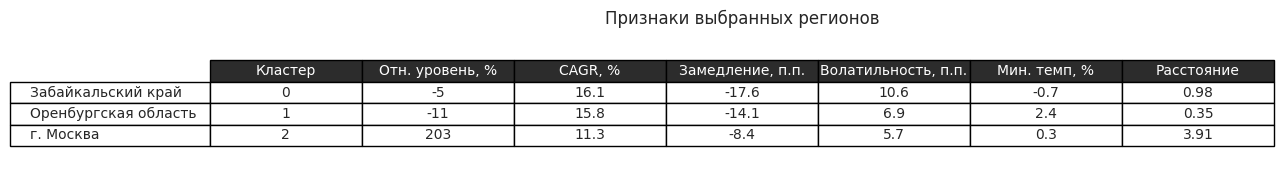

In [36]:
SELECTED = {0: 'Забайкальский край', 1: 'Оренбургская область', 2: 'г. Москва'}
COLORS   = {'Забайкальский край': 'coral', 'Оренбургская область': 'gray', 'г. Москва': 'steelblue'}

sel_view = pd.DataFrame({
    'Кластер':             list(SELECTED),
    'Отн. уровень, %':     [round((np.exp(X.loc[r, 'rel_level']) - 1) * 100) for r in SELECTED.values()],
    'CAGR, %':             [round(X.loc[r, 'cagr'] * 100, 1) for r in SELECTED.values()],
    'Замедление, п.п.':    [round(X.loc[r, 'slowdown'] * 100, 1) for r in SELECTED.values()],
    'Волатильность, п.п.': [round(X.loc[r, 'resid_vol'] * 100, 1) for r in SELECTED.values()],
    'Мин. темп, %':        [round(X.loc[r, 'min_growth'] * 100, 1) for r in SELECTED.values()],
    'Расстояние':          [round(dist[r], 2) for r in SELECTED.values()],
}, index=list(SELECTED.values()))
show_table(sel_view, 'Признаки выбранных регионов')

### 3.3 Базовая статистика

Тренд оценивается наклоном линейной регрессии значения на год (рублей в год), это средний абсолютный прирост за период. Наклон зависит от уровня: у Москвы он больше просто потому, что больше сам ряд. Поэтому рядом приведён наклон регрессии логарифма на год, пересчитанный в проценты: это средний темп роста, по нему регионы сравниваются независимо от уровня.

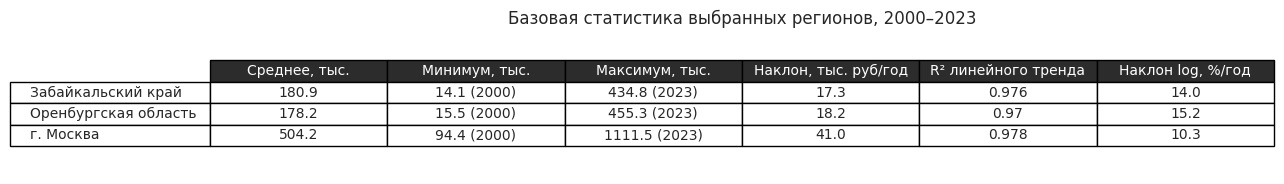

In [37]:
years = ts.index.year.values

def base_stats(s):
    slope, intercept = np.polyfit(years, s.values, 1)
    fitted           = intercept + slope * years
    r2               = 1 - ((s.values - fitted) ** 2).sum() / ((s.values - s.values.mean()) ** 2).sum()
    log_slope        = np.polyfit(years, np.log(s.values), 1)[0]
    return pd.Series({
        'Среднее, тыс.':        round(s.mean() / 1e3, 1),
        'Минимум, тыс.':        f'{s.min() / 1e3:.1f} ({s.idxmin().year})',
        'Максимум, тыс.':       f'{s.max() / 1e3:.1f} ({s.idxmax().year})',
        'Наклон, тыс. руб/год': round(slope / 1e3, 1),
        'R² линейного тренда':  round(r2, 3),
        'Наклон log, %/год':    round((np.exp(log_slope) - 1) * 100, 1),
    })

stats = pd.DataFrame({r: base_stats(series[r]) for r in SELECTED.values()}).T
show_table(stats, 'Базовая статистика выбранных регионов, 2000–2023')

Средние за период у Забайкальского края и Оренбургской области почти равны (180,9 и 178,2 тыс. руб.), у Москвы в 2,8 раза выше (504,2 тыс. руб.). Минимум у всех трёх в 2000 году, максимум в 2023 году. Единственное годовое снижение среди трёх регионов (Забайкальский край, −0,7% в 2019 году) уже в следующем году перекрыто ростом. Абсолютный наклон у Москвы 41,0 тыс. руб. в год против 17–18 тыс. у двух других регионов, а по наклону логарифма картина обратная: 10,3% в год у Москвы против 14,0% и 15,2%. R² линейного тренда 0,97–0,98 у всех трёх, но высокий R² здесь ничего не доказывает: любой монотонно растущий ряд хорошо описывается прямой. Видна ли кривизна, проверяется на этапе 4 по графикам и остаткам.

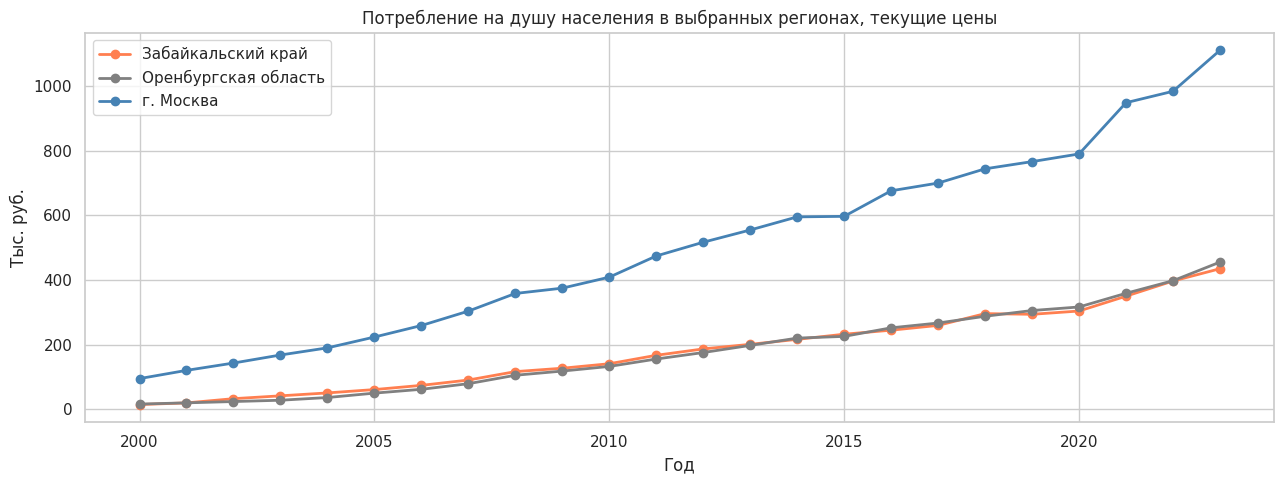

In [38]:
fig, ax = plt.subplots()
for region in SELECTED.values():
    ax.plot(years, series[region] / 1e3, color=COLORS[region], lw=2, marker='o', label=region)
ax.set(title='Потребление на душу населения в выбранных регионах, текущие цены', xlabel='Год', ylabel='Тыс. руб.')
ax.legend(); plt.tight_layout(); plt.show()

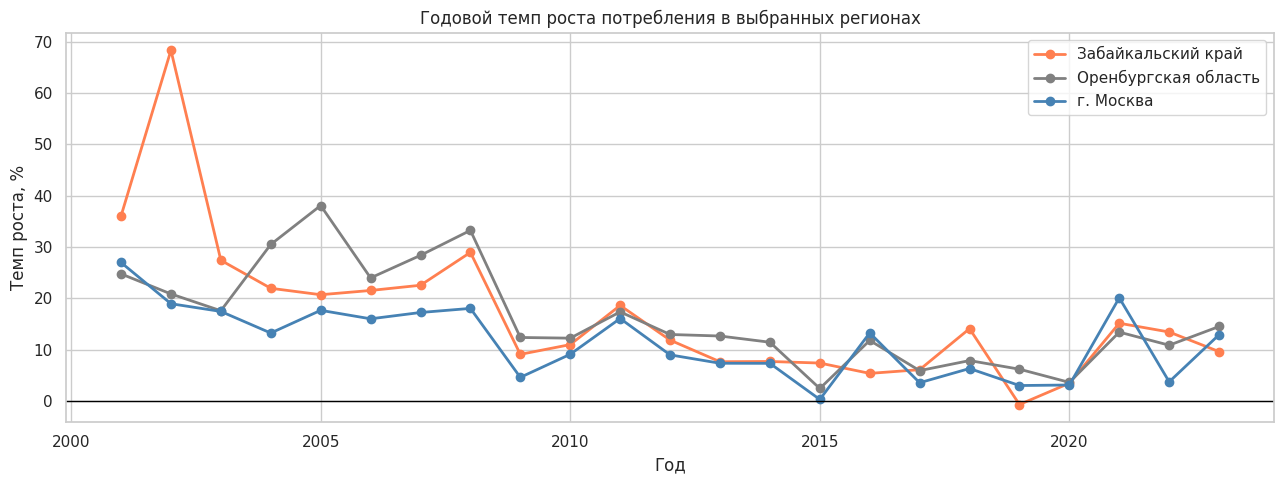

In [39]:
fig, ax = plt.subplots()
for region in SELECTED.values():
    ax.plot(growth.index, growth[region] * 100, color=COLORS[region], lw=2, marker='o', label=region)
ax.axhline(0, color='black', lw=1)
ax.set(title='Годовой темп роста потребления в выбранных регионах', xlabel='Год', ylabel='Темп роста, %')
ax.legend(); plt.tight_layout(); plt.show()

В уровнях Забайкальский край и Оренбургская область почти неразличимы: оба начинают с 14–16 тыс. руб. и приходят к 435–455 тыс. руб. Различие между ними, из-за которого они попали в разные кластеры, видно только на графике темпов: у Забайкальского края темп скачет сильнее (волатильность 10,6 п.п. против 6,9 п.п.) и сильнее затухает (−17,6 п.п. против −14,1 п.п.). Это хорошая проверка для моделей прогноза: на похожих уровнях они должны по-разному справиться с рядом, где колебания темпа больше. У Забайкальского края заметен рывок 2002 года (+68,4%), у Оренбургской области в 2015 году темп провалился до 2,4%. Москва отличается и уровнем (в 2,4–6,2 раза выше двух других регионов), и самым низким темпом с наименьшей волатильностью (5,7 п.п.), хотя и у неё есть провалы в 2015 году (+0,3%) и 2022 году (+3,7%) и всплеск в 2021 году (+20,1%).

## 4. Анализ выбранных регионов

### 4.1 Тренд: скользящее среднее и фильтр Ходрика–Прескотта

Тренд выделяется двумя способами. Центрированное скользящее среднее с окном 3 года сглаживает ряд без предположений о форме тренда, но теряет по точке с каждого края. Фильтр Ходрика–Прескотта (HP) даёт тренд на всём отрезке и раскладывает ряд на тренд и цикл. Параметр сглаживания λ = 6,25: это значение Равна–Улига для годовых данных, оно соответствует стандартному λ = 1600 для кварталов. Значение λ = 100, которое иногда берут для годовых рядов, на 24 точках почти выпрямляет тренд и переносит в «цикл» реальное замедление роста.

Оба фильтра используют соседей с обеих сторон, то есть будущее. Для описания ряда это допустимо, для признаков прогнозной модели нет, поэтому дальше в прогнозе они не участвуют.

Фильтр применяется к логарифму ряда: номинальный рост экспоненциальный, и в логарифмах циклическая компонента имеет смысл процентного отклонения от тренда, одинаково понятного для Москвы и Забайкалья.

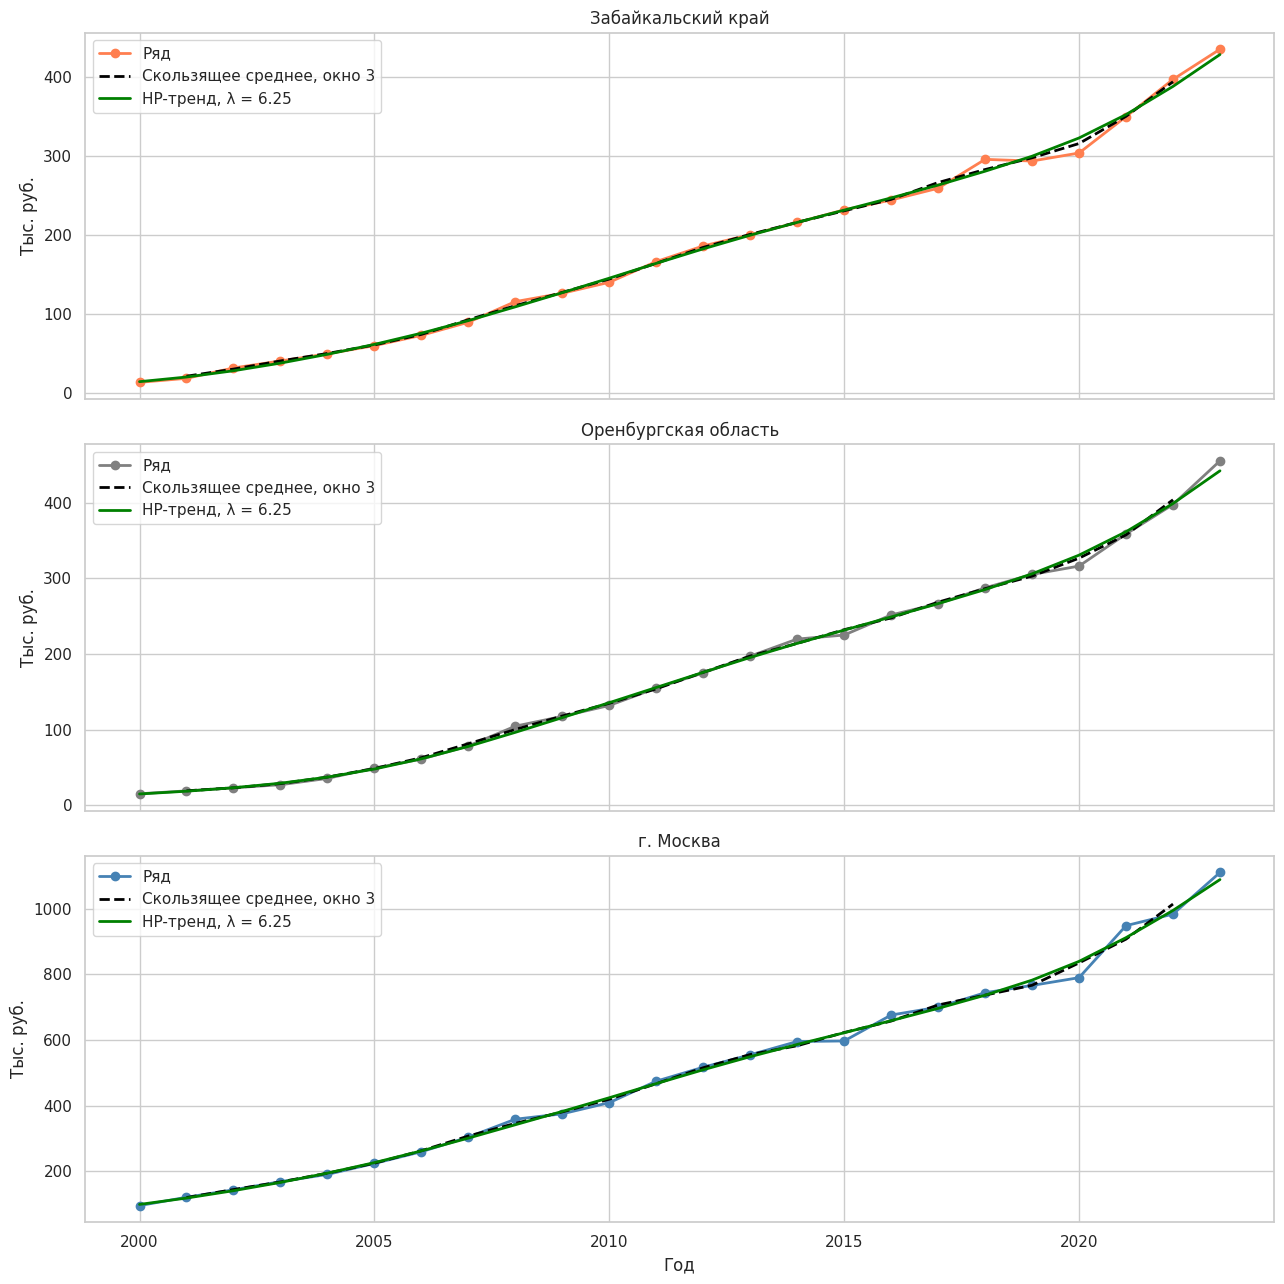

In [40]:
HP_LAMBDA = 6.25

decomp = {}
for region in SELECTED.values():
    log_s        = np.log(series[region])
    cycle, trend = hpfilter(log_s, lamb=HP_LAMBDA)
    decomp[region] = pd.DataFrame({
        'value':  series[region],
        'ma3':    series[region].rolling(3, center=True).mean(),
        'hp':     np.exp(trend),
        'cycle':  cycle * 100,
    })

fig, axes = plt.subplots(3, 1, figsize=(13, 13), sharex=True)
for ax, region in zip(axes, SELECTED.values()):
    d = decomp[region]
    ax.plot(years, d['value'] / 1e3, color=COLORS[region], lw=2, marker='o', label='Ряд')
    ax.plot(years, d['ma3'] / 1e3, color='black', lw=2, ls='--', label='Скользящее среднее, окно 3')
    ax.plot(years, d['hp'] / 1e3, color='green', lw=2, label=f'HP-тренд, λ = {HP_LAMBDA}')
    ax.set(title=region, ylabel='Тыс. руб.')
    ax.legend()
axes[-1].set_xlabel('Год')
plt.tight_layout(); plt.show()

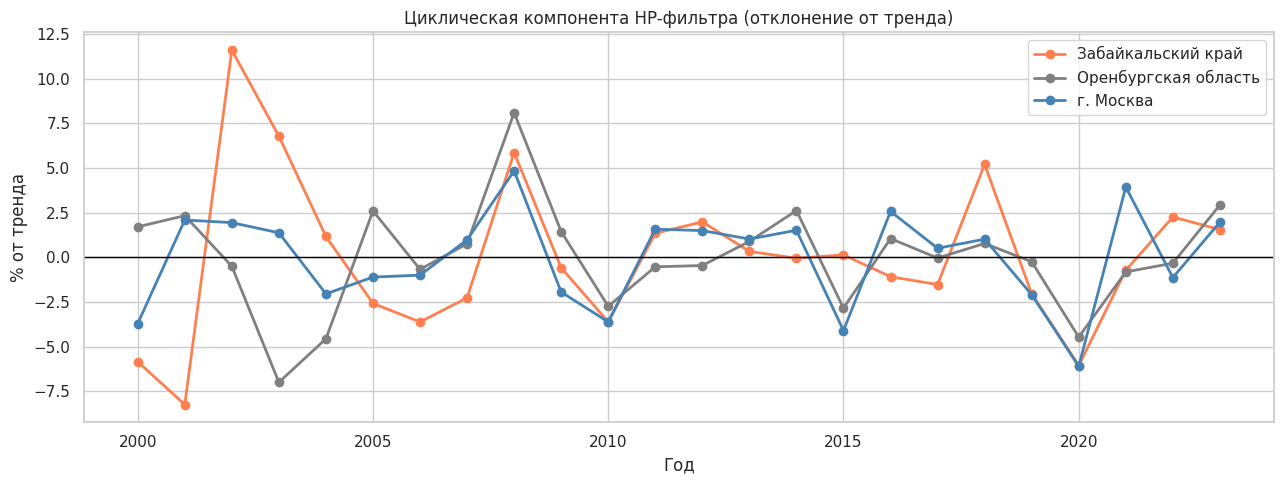

In [41]:
fig, ax = plt.subplots()
for region in SELECTED.values():
    ax.plot(years, decomp[region]['cycle'], color=COLORS[region], lw=2, marker='o', label=region)
ax.axhline(0, color='black', lw=1)
ax.set(title='Циклическая компонента HP-фильтра (отклонение от тренда)', xlabel='Год', ylabel='% от тренда')
ax.legend(); plt.tight_layout(); plt.show()

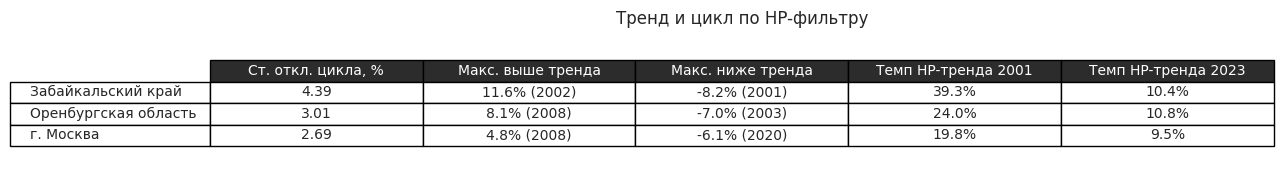

In [42]:
cycle_stats = pd.DataFrame({
    region: {
        'Ст. откл. цикла, %':  round(decomp[region]['cycle'].std(), 2),
        'Макс. выше тренда':   f"{decomp[region]['cycle'].max():.1f}% ({decomp[region]['cycle'].idxmax().year})",
        'Макс. ниже тренда':   f"{decomp[region]['cycle'].min():.1f}% ({decomp[region]['cycle'].idxmin().year})",
        'Темп HP-тренда 2001': f"{(decomp[region]['hp'].pct_change().iloc[1] * 100):.1f}%",
        'Темп HP-тренда 2023': f"{(decomp[region]['hp'].pct_change().iloc[-1] * 100):.1f}%",
    } for region in SELECTED.values()
}).T
show_table(cycle_stats, 'Тренд и цикл по HP-фильтру')

Тренд выражен у всех трёх регионов и является главной компонентой ряда: скользящее среднее и HP-тренд почти совпадают с самим рядом, отклонения от тренда обычно в пределах ±3–5%, наибольшее 11,6%. Тренд нелинейный. Темп HP-тренда за период упал у Забайкальского края с 39,3% до 10,4% в год, у Оренбургской области с 24,0% до 10,8%, у Москвы с 19,8% до 9,5%. К 2023 году трендовые темпы трёх регионов сошлись около 10% в год, хотя в начале периода различались вдвое. Сильнее всего тренд замедлился у Забайкальского края, слабее всего у Москвы.

Циклическая компонента самая большая у Забайкальского края (стандартное отклонение 4,39% от тренда), меньше у Оренбургской области (3,01%) и Москвы (2,69%). Самые большие отклонения Забайкальского края приходятся на 2001–2002 годы (−8,2% и +11,6%): это рывок роста на 68% в 2002 году. Край образован в 2008 году объединением Читинской области и Агинского Бурятского АО, и данные за ранние годы пересчитаны на новые границы, поэтому скачок 2002 года может быть отчасти методическим. Это гипотеза, в данных её проверить нельзя.

Отклонения от тренда синхронны у всех трёх регионов в кризисные годы. В 2008 году ряд выше тренда (Оренбургская область +8,1%, Забайкальский край +5,8%, Москва +4,8%), в 2010 году ниже, в 2020 году ниже у всех (от −4,5% до −6,1%, у Москвы это минимум за период). В 2015 году ниже тренда Москва (−4,1%) и Оренбургская область (−2,8%), а Забайкальский край на тренде. Колебания с периодом в несколько лет есть, но фиксированного периода у них нет: это реакция на кризисы 2008–2009, 2014–2015 и 2020 годов, а не регулярный цикл. HP-тренд на краях ряда (2000–2001 и 2022–2023 годы) менее надёжен: у фильтра нет соседей с одной стороны, и тренд притягивается к крайним точкам.

### 4.2 Почему нет сезонной декомпозиции

Сезонность это колебание с фиксированным периодом внутри года (месяц, квартал, день недели), и её оценивают, сравнивая одинаковые фазы разных периодов: все январи между собой. В годовом ряду одна точка на год, у неё нет фаз внутри периода, поэтому сезонной компоненте не из чего возникнуть: годовое значение уже сумма по всем сезонам. `seasonal_decompose` с period=1 вернул бы нулевую сезонность, а с любым period > 1 нашёл бы «сезонность» с периодом в несколько лет, которой нет в экономическом смысле и которую на 24 точках нельзя отличить от шума или от цикла. Многолетние колебания здесь описываются как цикл (отклонение от тренда), что и сделано выше.

### 4.3 Тест Дики–Фуллера

Нулевая гипотеза расширенного теста Дики–Фуллера (ADF): у ряда есть единичный корень, то есть ряд нестационарен. Отвергнуть её при p < 0,05 значит считать ряд стационарным (для варианта с трендом стационарным вокруг линейного тренда).

Тест проводится для пяти вариантов ряда, чтобы найти порядок интегрирования d для ARIMA:

1. исходный уровень, регрессия с константой и трендом (`ct`), потому что ряд явно растёт;
2. логарифм, тоже `ct`;
3. первая разность логарифма, то есть логарифмический темп роста, регрессия с константой (`c`): у темпа ненулевое среднее;
4. та же первая разность, но с трендом (`ct`): проверка, не объясняется ли нестационарность темпа его плавным снижением;
5. вторая разность логарифма (изменение темпа), `c`.

Число лагов выбирается по AIC, но не больше 3: на 22–23 точках после разностей каждый лишний лаг съедает степени свободы. У теста на такой короткой выборке низкая мощность, поэтому «не отвергли» означает «данных не хватило, чтобы показать стационарность», а не доказательство единичного корня. Это учитывается при интерпретации.

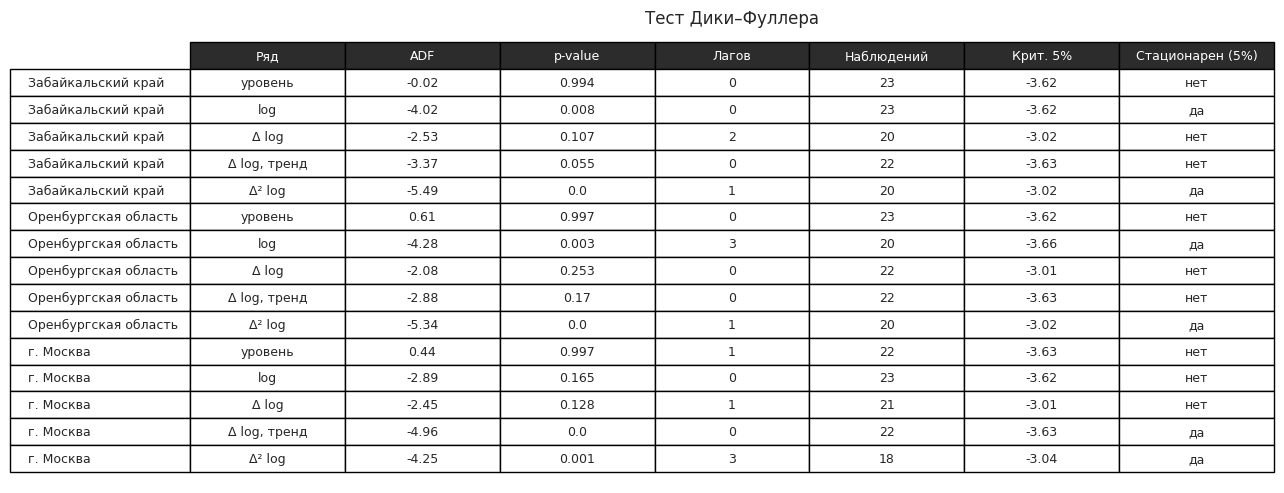

In [43]:
def adf_row(x, regression):
    stat, p, lags, nobs, crit, _ = adfuller(x.dropna(), regression=regression, maxlag=3, autolag='AIC')
    return {'ADF': round(stat, 2), 'p-value': round(p, 3), 'Лагов': lags, 'Наблюдений': nobs,
            'Крит. 5%': round(crit['5%'], 2), 'Стационарен (5%)': 'да' if p < 0.05 else 'нет'}

adf_rows = []
for region in SELECTED.values():
    log_s = np.log(series[region])
    for name, x, reg in [('уровень', series[region], 'ct'),
                         ('log', log_s, 'ct'),
                         ('Δ log', log_s.diff(), 'c'),
                         ('Δ log, тренд', log_s.diff(), 'ct'),
                         ('Δ² log', log_s.diff().diff(), 'c')]:
        adf_rows.append({'Регион': region, 'Ряд': name, **adf_row(x, reg)})

adf_table = pd.DataFrame(adf_rows).set_index('Регион')
show_table(adf_table, 'Тест Дики–Фуллера', font=9, height=0.3)

Уровень ряда нестационарен у всех трёх регионов (p > 0,99), это ожидаемо для ряда с сильным ростом.

Для логарифма и первой разности результаты на первый взгляд противоречат друг другу. У Забайкальского края и Оренбургской области тест признаёт логарифм стационарным вокруг линейного тренда (p = 0,008 и 0,003), а первую разность логарифма нестационарной (p = 0,107 и 0,253). Если бы логарифм действительно колебался вокруг прямой, его разность колебалась бы вокруг постоянного темпа и была бы стационарной. Противоречие объясняется тем, что тренд нелинейный: темп роста не постоянен, а падает с 25–40% до 10% (раздел 4.1). Для теста с константой снижающийся темп выглядит как ряд без возврата к среднему. В варианте с трендом статистика для разности логарифма становится сильнее, но у Забайкальского края (−3,37) и Оренбургской области (−2,88) не достигает критического значения около −3,6, а у Москвы (−4,96) достигает: темп роста Москвы можно считать стационарным вокруг плавно снижающегося тренда. У Москвы логарифм нестационарен и с трендом (p = 0,165).

Вторая разность логарифма стационарна у всех трёх регионов (p ≤ 0,001). Формально тест указывает на порядок интегрирования d = 2 для логарифма. При этом на 20–23 наблюдениях мощность теста низкая, и по разные стороны границы 5% оказываются похожие ряды, поэтому результат теста это аргумент, а не решение. На этапе 5 сравниваются оба варианта: d = 1 со сносом (темп роста колеблется вокруг постоянного среднего) и d = 2 (темп роста сам блуждает и прогноз продолжает его последнее изменение).

### 4.4 ACF и PACF

Автокорреляции строятся для ряда, который тест признал стационарным: по уровням ACF нестационарного ряда медленно убывает от единицы и отражает только тренд, по ней порядки ARMA не прочитать. Основной вариант это первая разность логарифма (темп роста), для сравнения справа показана ACF уровня.

Число лагов 10, это меньше половины длины ряда после разности (23 точки): PACF на большем числе лагов оценивается ненадёжно. Закрашенная полоса это 95% доверительный интервал для нулевой автокорреляции: для лага 1 примерно ±1,96/√23 ≈ ±0,41, для дальних лагов ACF полоса шире (формула Бартлетта учитывает предыдущие автокорреляции). На 23 точках значимыми окажутся только сильные зависимости, слабые утонут в интервале.

Правила чтения. Если ACF обрывается после лага q, а PACF затухает, это MA(q). Если PACF обрывается после лага p, а ACF затухает, это AR(p). Если ни одна не выходит за интервал, разность ряда близка к белому шуму, и подходит ARIMA(0, d, 0), то есть случайное блуждание со сносом.

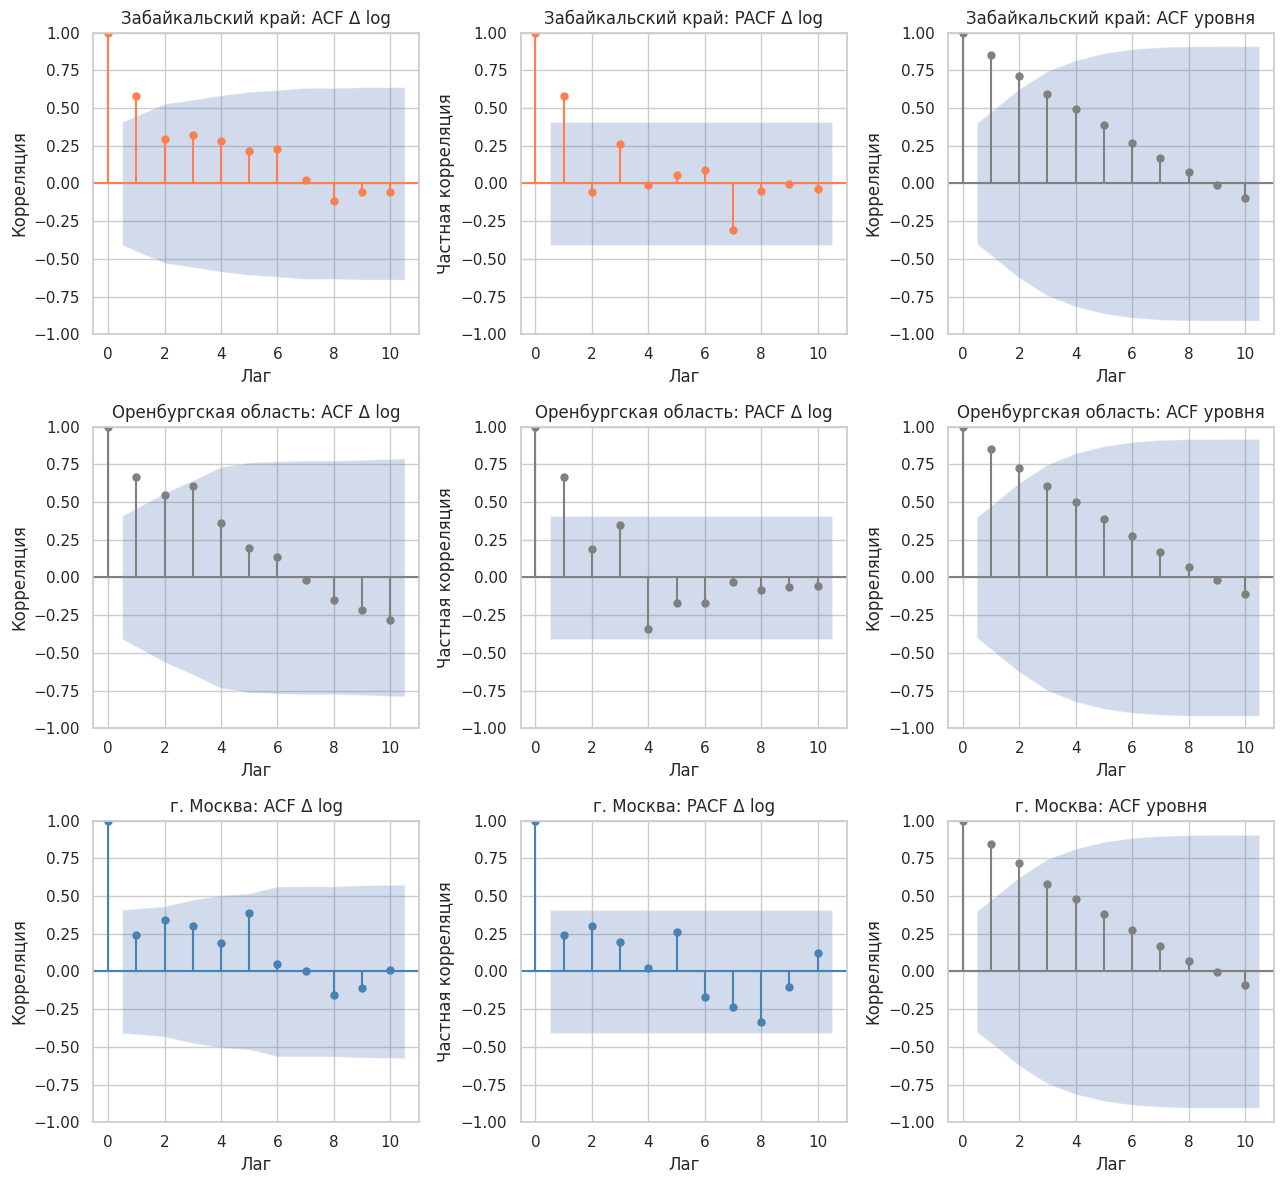

In [44]:
LAGS = 10

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for row, region in zip(axes, SELECTED.values()):
    dlog = np.log(series[region]).diff().dropna()
    plot_acf(dlog, lags=LAGS, ax=row[0], color=COLORS[region], vlines_kwargs={'colors': COLORS[region]})
    plot_pacf(dlog, lags=LAGS, ax=row[1], method='ywm', color=COLORS[region], vlines_kwargs={'colors': COLORS[region]})
    plot_acf(series[region], lags=LAGS, ax=row[2], color='gray', vlines_kwargs={'colors': 'gray'})
    row[0].set(title=f'{region}: ACF Δ log', xlabel='Лаг', ylabel='Корреляция')
    row[1].set(title=f'{region}: PACF Δ log', xlabel='Лаг', ylabel='Частная корреляция')
    row[2].set(title=f'{region}: ACF уровня', xlabel='Лаг', ylabel='Корреляция')
plt.tight_layout(); plt.show()

Граница значимости ±0.41


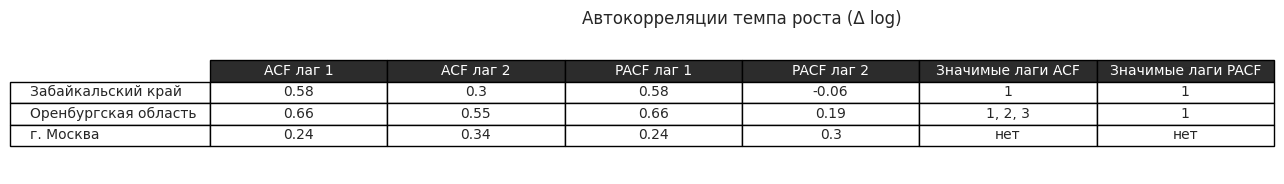

In [45]:
conf  = 1.96 / np.sqrt(len(years) - 1)
acf_rows = []
for region in SELECTED.values():
    dlog = np.log(series[region]).diff().dropna()
    a, p = acf(dlog, nlags=LAGS), pacf(dlog, nlags=LAGS, method='ywm')
    acf_rows.append({
        'Регион':              region,
        'ACF лаг 1':           round(a[1], 2),
        'ACF лаг 2':           round(a[2], 2),
        'PACF лаг 1':          round(p[1], 2),
        'PACF лаг 2':          round(p[2], 2),
        'Значимые лаги ACF':   ', '.join(str(i) for i in range(1, LAGS + 1) if abs(a[i]) > conf) or 'нет',
        'Значимые лаги PACF':  ', '.join(str(i) for i in range(1, LAGS + 1) if abs(p[i]) > conf) or 'нет',
    })

acf_table = pd.DataFrame(acf_rows).set_index('Регион')
print(f'Граница значимости ±{conf:.2f}')
show_table(acf_table, 'Автокорреляции темпа роста (Δ log)')

ACF уровня одинакова у всех трёх регионов: медленное линейное убывание от 0,85 на лаге 1 до нуля к лагу 9. Это подпись тренда, а не структуры ARMA, по ней регионы неразличимы. Поэтому порядки читаются по разности логарифма.

Забайкальский край: ACF разности логарифма значима только на лаге 1 (0,58), дальше положительна и медленно убывает в пределах интервала (0,30, 0,32, 0,28 на лагах 2–4). PACF значима на лаге 1 (0,58) и обрывается: на лаге 2 уже −0,06. Это картина AR(1): p = 1, q = 0.

Оренбургская область: ACF значима на лагах 1–3 (0,66, 0,55, 0,61) и затухает, PACF значима только на лаге 1 (0,66), на лаге 2 0,19. Это тоже AR(1), p = 1, q = 0, с более сильной зависимостью, чем у Забайкальского края.

Москва: ни ACF, ни PACF не выходят за интервал (наибольшая ACF 0,39 на лаге 5, наибольшая PACF 0,30 на лаге 2). Разность логарифма неотличима от белого шума, гипотеза p = 0, q = 0, то есть случайное блуждание со сносом в логарифмах.

У Забайкальского края и Оренбургской области положительные автокорреляции на многих лагах подряд характерны для ряда с медленно меняющимся средним: годы высокого темпа идут подряд в начале периода, годы низкого темпа в конце. Значит, AR(1) с высоким коэффициентом частично описывает не инерцию темпа, а его тренд, и то же самое может сделать вторая разность. Отсюда две гипотезы для каждого региона, которые сравниваются на этапе 5 с автоматическим подбором по AIC:

1. Забайкальский край: ARIMA(1, 1, 0) со сносом по логарифму, альтернатива ARIMA(0, 2, 1).
2. Оренбургская область: ARIMA(1, 1, 0) со сносом, альтернатива ARIMA(0, 2, 1).
3. Москва: ARIMA(0, 1, 0) со сносом, альтернатива ARIMA(0, 2, 1).

ARIMA(0, 2, 1) в альтернативе выбрана потому, что вторая разность ряда с плавно меняющимся темпом обычно даёт отрицательную автокорреляцию на лаге 1, которую описывает MA(1).

### 4.5 Сравнение регионов

Тренд выражен у всех трёх регионов, и в процентах он сильнее всего у Оренбургской области (наклон логарифма 15,2% в год против 14,0% у Забайкальского края и 10,3% у Москвы), а в рублях у Москвы (41,0 тыс. руб. в год против 17–18 тыс.). Замедление тренда сильнее всего у Забайкальского края (трендовый темп с 39,3% до 10,4%), слабее всего у Москвы (с 19,8% до 9,5%).

Волатильность выше всего у Забайкальского края: стандартное отклонение цикла 4,39% от тренда, волатильность темпа 10,6 п.п. У Оренбургской области 3,01% и 6,9 п.п., у Москвы 2,69% и 5,7 п.п. Порядок одинаков по обеим мерам.

Стационарность: ни один ряд не стационарен в уровнях. Логарифм стационарен вокруг тренда по тесту у Забайкальского края и Оренбургской области, у Москвы нет. Темп роста (разность логарифма) стационарен вокруг тренда только у Москвы. Вторая разность логарифма стационарна у всех трёх.

Автокорреляции темпа различаются сильнее всего. У Оренбургской области темп самый инерционный (ACF лага 1 0,66, значимы три лага), у Забайкальского края инерция слабее (0,58, значим один лаг), у Москвы значимой автокорреляции нет. Москва при этом самый «предсказуемый» ряд в смысле плавности, но её отклонения от среднего темпа не повторяются из года в год, а у двух других регионов быстрые и медленные годы идут сериями. Это различие в памяти темпа и проверяется сравнением моделей на этапе 5.

## 5. Прогнозирование

### 5.1 Схема эксперимента

Обучающая выборка 2000–2017 годы (18 точек, 75% ряда), тестовая 2018–2023 годы (6 точек). В тест попадают обычный год (2018), спад 2020 года, восстановление 2021 года и 2022 год, то есть модели проверяются на разных режимах, а не только на спокойном отрезке. Будущий прогноз строится на 3 года (2024–2026) для всех регионов: при 24 годовых точках дальний горизонт был бы экстраполяцией тренда без проверки, а три года сравнимы с длиной теста.

Модели:

1. Наивный прогноз `NaiveForecaster(strategy="last")`: все будущие значения равны последнему наблюдению. Это бейзлайн из задания.
2. Наивный прогноз со сносом `NaiveForecaster(strategy="drift")`: прямая через первую и последнюю точку обучения. Растущий ряд плоский прогноз отстаёт заведомо, поэтому снос служит вторым, более честным бейзлайном: модель, которая его не обгоняет, ничего не выучила сверх среднего прироста.
3. Holt: экспоненциальное сглаживание с аддитивным трендом, по логарифму ряда. Аддитивный тренд в логарифмах означает постоянный темп роста, который модель подстраивает по последним годам.
4. ARIMA по логарифму, порядок подбирается по AIC на обучении на сетке p, q от 0 до 2 отдельно для d = 1 (со сносом) и d = 2 (без константы). AIC моделей с разным d не сравнивается, потому что они описывают разные ряды (первые и вторые разности), поэтому на тест выходят обе лучшие модели, и выбор d делает проверка на тесте.

Holt и ARIMA обучаются на логарифме по двум причинам. В абсолютных рублях ошибки поздних лет в десятки раз больше ранних, и модель подстраивалась бы под последние годы. И экспоненциальный рост в логарифмах становится линейным, а это та форма тренда, которую обе модели умеют продолжать. Прогноз переводится обратно экспонентой, метрики считаются на исходной шкале в рублях.

In [46]:
TRAIN_END = '2017'
TEST_START = '2018'
H_FUTURE  = 3
MAX_PQ    = 2

def rmse(y, f):
    return float(np.sqrt(np.mean((y.values - f.values) ** 2)))

def mape(y, f):
    return float(np.mean(np.abs((y.values - f.values) / y.values)) * 100)

def fc_naive(train, h, strategy):
    return NaiveForecaster(strategy=strategy).fit(train).predict(fh=np.arange(1, h + 1))

def fc_holt(train, h):
    fit = ExponentialSmoothing(np.log(train), trend='add', initialization_method='estimated').fit()
    return np.exp(fit.forecast(h))

def fc_arima(train, h, order):
    trend = 't' if order[1] == 1 else 'n'
    fit   = ARIMA(np.log(train), order=order, trend=trend).fit()
    return np.exp(fit.forecast(h))

def select_arima(train, d):
    trend, rows = ('t' if d == 1 else 'n'), []
    for p in range(MAX_PQ + 1):
        for q in range(MAX_PQ + 1):
            try:
                fit = ARIMA(np.log(train), order=(p, d, q), trend=trend).fit()
                rows.append({'order': (p, d, q), 'AIC': round(fit.aic, 2)})
            except Exception:
                continue
    return pd.DataFrame(rows).sort_values('AIC', ignore_index=True)

### 5.2 Подбор порядка ARIMA

Таблица показывает три лучшие модели по AIC для каждого d и место гипотез из раздела 4.4. Подбор идёт только по обучающей выборке, тест в нём не участвует.

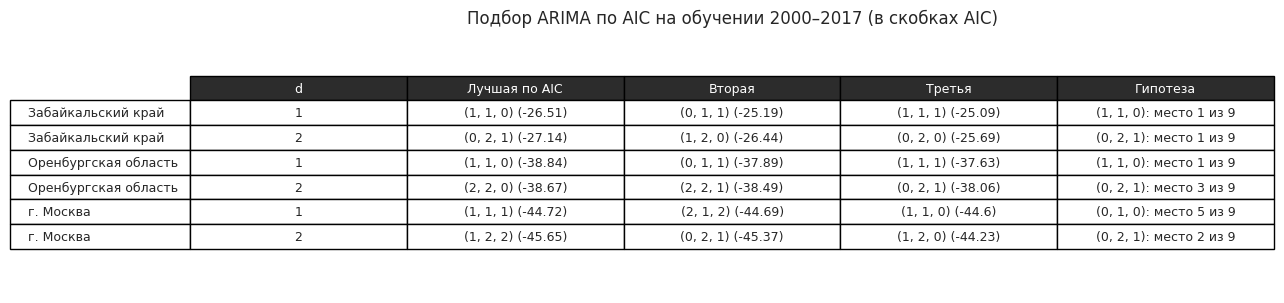

In [47]:
HYPOTHESES = {
    'Забайкальский край':   [(1, 1, 0), (0, 2, 1)],
    'Оренбургская область': [(1, 1, 0), (0, 2, 1)],
    'г. Москва':            [(0, 1, 0), (0, 2, 1)],
}

orders, aic_rows = {}, []
for region in SELECTED.values():
    train = series[region][:TRAIN_END]
    for d in [1, 2]:
        grid = select_arima(train, d)
        orders[(region, d)] = grid.loc[0, 'order']
        hyp  = [h for h in HYPOTHESES[region] if h[1] == d][0]
        rank = grid.index[grid['order'] == hyp][0] + 1
        aic_rows.append({
            'Регион': region, 'd': d,
            'Лучшая по AIC': f"{grid.loc[0, 'order']} ({grid.loc[0, 'AIC']})",
            'Вторая':        f"{grid.loc[1, 'order']} ({grid.loc[1, 'AIC']})",
            'Третья':        f"{grid.loc[2, 'order']} ({grid.loc[2, 'AIC']})",
            'Гипотеза':      f"{hyp}: место {rank} из {len(grid)}",
        })

show_table(pd.DataFrame(aic_rows).set_index('Регион'), 'Подбор ARIMA по AIC на обучении 2000–2017 (в скобках AIC)', font=9)

Гипотезы из раздела 4.4 подтвердились в четырёх случаях из шести. У Забайкальского края обе гипотезы, (1, 1, 0) и (0, 2, 1), лучшие по AIC в своём d, у Оренбургской области (1, 1, 0) лучшая при d = 1. Расхождения: у Оренбургской области при d = 2 лучшая (2, 2, 0), гипотеза (0, 2, 1) третья; у Москвы при d = 1 лучшая (1, 1, 1), а гипотеза (0, 1, 0) только пятая, при d = 2 лучшая (1, 2, 2), гипотеза (0, 2, 1) вторая. Разница AIC между тремя лучшими моделями внутри каждого d не больше 1,5 единицы, на 18 точках такие модели по AIC практически неразличимы. Поэтому окончательный выбор делает тест.

### 5.3 Прогноз на тестовую выборку и метрики

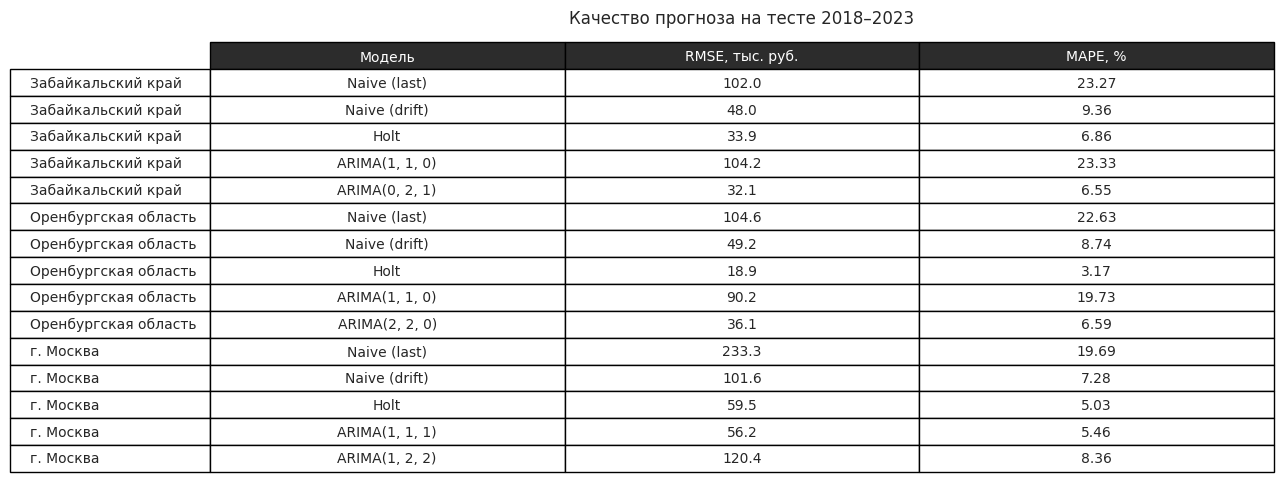

In [48]:
def model_set(region):
    return {
        'Naive (last)':                      lambda tr, h: fc_naive(tr, h, 'last'),
        'Naive (drift)':                     lambda tr, h: fc_naive(tr, h, 'drift'),
        'Holt':                              fc_holt,
        f'ARIMA{orders[(region, 1)]}':       lambda tr, h, o=orders[(region, 1)]: fc_arima(tr, h, o),
        f'ARIMA{orders[(region, 2)]}':       lambda tr, h, o=orders[(region, 2)]: fc_arima(tr, h, o),
    }

test_fc, metric_rows = {}, []
for region in SELECTED.values():
    y     = series[region]
    train = y[:TRAIN_END]
    test  = y[TEST_START:]
    for name, fn in model_set(region).items():
        f = fn(train, len(test))
        f.index = test.index
        test_fc[(region, name)] = f
        metric_rows.append({'Регион': region, 'Модель': name,
                            'RMSE, тыс. руб.': round(rmse(test, f) / 1e3, 1),
                            'MAPE, %':         round(mape(test, f), 2)})

metrics = pd.DataFrame(metric_rows)
show_table(metrics.set_index('Регион'), 'Качество прогноза на тесте 2018–2023', height=0.3)

In [49]:
best = metrics.loc[metrics.groupby('Регион')['RMSE, тыс. руб.'].idxmin()].set_index('Регион')
BEST = best['Модель'].to_dict()

summary = metrics.pivot(index='Регион', columns='Модель', values='MAPE, %')
summary['Лучшая (RMSE)'] = pd.Series(BEST)
summary['Лучше Naive (last)'] = [
    'да' if best.loc[r, 'MAPE, %'] < summary.loc[r, 'Naive (last)'] else 'нет' for r in summary.index]
summary['Лучше Naive (drift)'] = [
    'да' if best.loc[r, 'MAPE, %'] < summary.loc[r, 'Naive (drift)'] else 'нет' for r in summary.index]
summary = summary.reindex(list(SELECTED.values()))
summary

Модель,"ARIMA(0, 2, 1)","ARIMA(1, 1, 0)","ARIMA(1, 1, 1)","ARIMA(1, 2, 2)","ARIMA(2, 2, 0)",Holt,Naive (drift),Naive (last),Лучшая (RMSE),Лучше Naive (last),Лучше Naive (drift)
Регион,,,,,,,,,,,
Забайкальский край,6.55,23.33,NaN,NaN,NaN,6.86,9.36,23.27,"ARIMA(0, 2, 1)",да,да
Оренбургская область,NaN,19.73,NaN,NaN,6.59,3.17,8.74,22.63,Holt,да,да
г. Москва,NaN,NaN,5.46,8.36,NaN,5.03,7.28,19.69,"ARIMA(1, 1, 1)",да,да


Наивный прогноз «последнее значение» ошибается на 19,7–23,3%: на растущем ряде за 6 лет он отстаёт на всю накопленную инфляцию. Его обгоняют все модели, кроме одной. Наивный прогноз со сносом ошибается на 7,3–9,4%, и это более содержательная планка.

Главный провал это ARIMA(1, 1, 0) со сносом у Забайкальского края и Оренбургской области: MAPE 23,3% и 19,7%, хуже сноса, а у Забайкальского края хуже даже плоского прогноза. На графике ниже её прогноз уходит вверх от факта. Причина та, о которой предупреждал раздел 4.4. Снос модели это средний темп роста за 2001–2017 годы, куда входят годы с ростом 25–40%, а AR(1) с большим коэффициентом возвращает прогнозный темп от последних 6–8% к этому среднему. Модель с d = 1 предполагает, что средний темп постоянен, а у этих регионов он десять лет падал. Значимая PACF на лаге 1 описывала тренд темпа, а не его инерцию.

Лучшие модели по RMSE:

1. Забайкальский край: ARIMA(0, 2, 1), MAPE 6,55%, RMSE 32,1 тыс. руб. Holt почти так же точен (6,86% и 33,9 тыс.). Близость не случайна: метод Холта с аддитивным трендом эквивалентен ARIMA(0, 2, 2), и обе модели продолжают последний темп роста, а не многолетнее среднее.
2. Оренбургская область: Holt, MAPE 3,17%, RMSE 18,9 тыс. руб. Это самый точный прогноз среди трёх регионов, вдвое точнее лучшей ARIMA (2, 2, 0) с 6,59% и почти втрое точнее сноса (8,74%).
3. Москва: ARIMA(1, 1, 1) со сносом, RMSE 56,2 тыс. руб. против 59,5 у Holt. По MAPE порядок обратный: Holt 5,03%, ARIMA 5,46%. RMSE сильнее штрафует ошибки последних лет, где значения выше, и там точнее ARIMA, MAPE взвешивает годы одинаково. Разница невелика, правило выбора по RMSE было зафиксировано до запуска, поэтому лучшей считается ARIMA. У Москвы d = 1 со сносом работает, потому что её темп замедлялся слабее всех (раздел 4.1), а ADF признал её темп стационарным вокруг тренда.

Во всех трёх регионах лучшая модель обгоняет оба наивных прогноза. Выигрыш у сноса по MAPE от 1,8 п.п. у Москвы (5,46% против 7,28%) до 5,6 п.п. у Оренбургской области (3,17% против 8,74%).

In [50]:
test_err = pd.DataFrame({
    region: (series[region][TEST_START:] / test_fc[(region, BEST[region])] - 1) * 100
    for region in SELECTED.values()
}).round(1)
test_err.index = test_err.index.year
print('Ошибка лучшей модели на тесте, % (факт / прогноз − 1):')
test_err.T

Ошибка лучшей модели на тесте, % (факт / прогноз − 1):


year,2018,2019,2020,2021,2022,2023
Забайкальский край,7.2,0.1,-2.7,5.4,12.3,15.8
Оренбургская область,0.2,-1.1,-4.8,0.3,3.3,10.0
г. Москва,-1.3,-6.0,-10.7,-1.7,-6.7,-4.0


Ошибки лучших моделей на тесте по годам систематические, а не случайные. Забайкальский край в 2018–2020 годах прогнозируется хорошо (от −2,7% до +7,2%), а к 2022–2023 годам модель отстаёт от факта на 12,3% и 15,8%: она продолжила темп 2014–2017 годов (5–8% в год), а в 2021–2023 годах рост был 15,1%, 13,4% и 9,6%. У Оренбургской области ошибка в пределах ±5% до 2022 года и +10,0% в 2023 году по той же причине. Москву модель переоценивает во все шесть лет (от −1,3% до −10,7%, максимум в 2020 году), в среднем на 5,1%.

### 5.4 Прогноз на 2024–2026 годы

Лучшая модель каждого региона переобучается на всём ряду 2000–2023 и строит прогноз на 3 года. Для ARIMA 95% интервал берётся из модели (`get_forecast`), для Holt он оценивается симуляцией 2000 траекторий с остатками модели, для наивных моделей из `predict_interval` sktime. Интервалы строятся в логарифмах и переводятся экспонентой, поэтому они несимметричны: вверх шире, чем вниз.

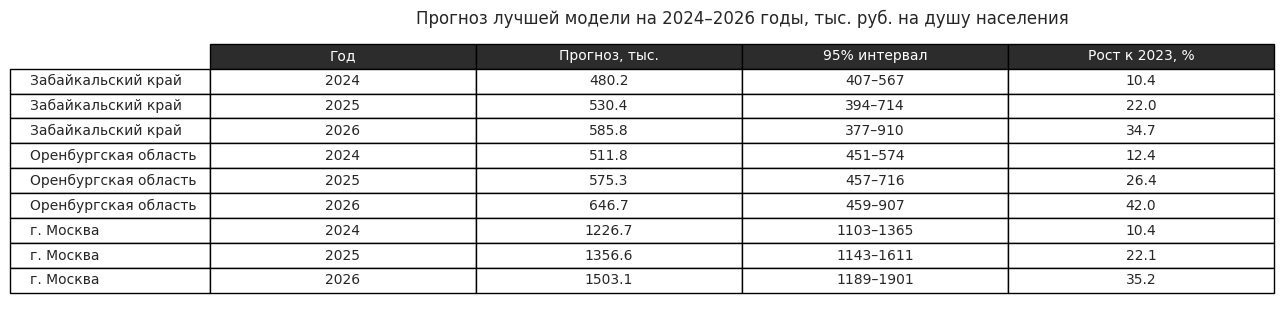

In [51]:
def future_forecast(y, name, h=H_FUTURE, alpha=0.05):
    log_y = np.log(y)
    if name.startswith('ARIMA'):
        order = tuple(int(v) for v in name[6:-1].split(','))
        fit   = ARIMA(log_y, order=order, trend='t' if order[1] == 1 else 'n').fit()
        fc    = fit.get_forecast(h)
        ci    = fc.conf_int(alpha=alpha)
        return pd.DataFrame({'forecast': np.exp(fc.predicted_mean),
                             'lower': np.exp(ci.iloc[:, 0]), 'upper': np.exp(ci.iloc[:, 1])})
    if name == 'Holt':
        fit  = ExponentialSmoothing(log_y, trend='add', initialization_method='estimated').fit()
        sims = fit.simulate(h, repetitions=2000, error='add', anchor='end', rng=np.random.default_rng(42))
        fc   = np.exp(fit.forecast(h))
        return pd.DataFrame({'forecast': fc,
                             'lower': np.exp(np.quantile(np.asarray(sims), alpha / 2, axis=1)),
                             'upper': np.exp(np.quantile(np.asarray(sims), 1 - alpha / 2, axis=1))}, index=fc.index)
    strategy = 'last' if 'last' in name else 'drift'
    f    = NaiveForecaster(strategy=strategy).fit(y)
    fh   = np.arange(1, h + 1)
    pi   = f.predict_interval(fh=fh, coverage=1 - alpha)
    return pd.DataFrame({'forecast': f.predict(fh=fh),
                         'lower': pi.iloc[:, 0].values, 'upper': pi.iloc[:, 1].values}, index=f.predict(fh=fh).index)

future = {region: future_forecast(series[region], BEST[region]) for region in SELECTED.values()}

future_rows = []
for region, f in future.items():
    last = series[region].iloc[-1]
    for period, row in f.iterrows():
        future_rows.append({'Регион': region, 'Год': period.year,
                            'Прогноз, тыс.':   round(row['forecast'] / 1e3, 1),
                            '95% интервал':    f"{row['lower'] / 1e3:.0f}–{row['upper'] / 1e3:.0f}",
                            'Рост к 2023, %':  round((row['forecast'] / last - 1) * 100, 1)})
future_table = pd.DataFrame(future_rows).set_index('Регион')
show_table(future_table, 'Прогноз лучшей модели на 2024–2026 годы, тыс. руб. на душу населения', height=0.3)

Лучшие модели прогнозируют рост в среднем 10,4% в год у Забайкальского края (до 585,8 тыс. руб. в 2026 году), 10,6% у Москвы (до 1503,1 тыс. руб.) и 12,4% у Оренбургской области (до 646,7 тыс. руб.). Оренбургская область получает самый высокий темп, потому что Holt продолжает текущий тренд, а последние три года области (13,4%, 10,9%, 14,5%) были быстрыми. По прогнозу Оренбургская область обгоняет Забайкальский край: в 2023 году Забайкалье составляло 95% оренбургского уровня, в 2026 году будет 91%.

Ширина интервалов показывает неопределённость. У Забайкальского края интервал на 2026 год 377–910 тыс. руб.: его нижняя граница ниже уровня 2023 года (434,8 тыс. руб.). Модель с d = 2 позволяет блуждать самому темпу роста, и неопределённость растёт с горизонтом быстрее, чем у моделей с d = 1. У Москвы интервал 1189–1901 тыс. руб., его нижняя граница на 7% выше уровня 2023 года. Интервалы предполагают, что будущие шоки будут не сильнее прошлых, поэтому реальная неопределённость больше.

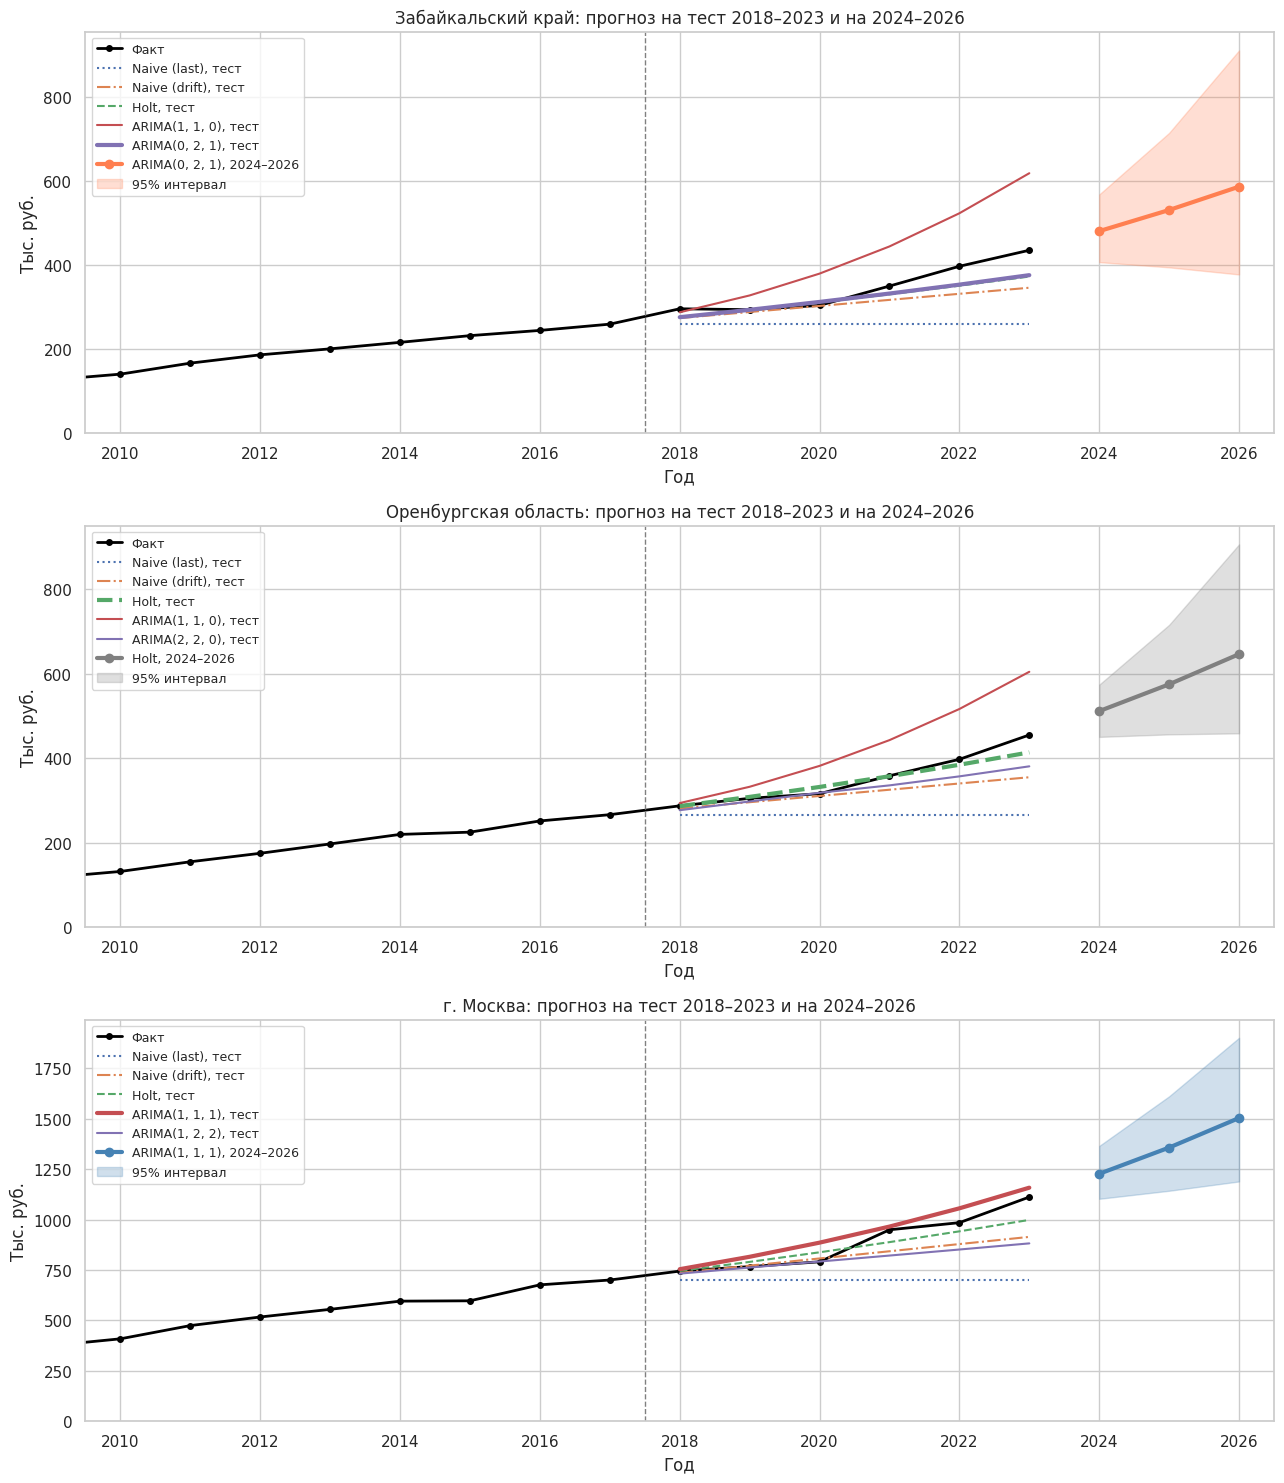

In [52]:
MODEL_STYLE = {'Naive (last)': ':', 'Naive (drift)': '-.', 'Holt': '--'}

fig, axes = plt.subplots(3, 1, figsize=(13, 15))
for ax, region in zip(axes, SELECTED.values()):
    y = series[region]
    ax.plot(y.index.year, y / 1e3, color='black', lw=2, marker='o', ms=4, label='Факт')
    for name in model_set(region):
        f  = test_fc[(region, name)]
        lw = 3 if name == BEST[region] else 1.5
        ax.plot(f.index.year, f / 1e3, lw=lw, ls=MODEL_STYLE.get(name, '-'), label=f'{name}, тест')
    fut = future[region]
    ax.plot(fut.index.year, fut['forecast'] / 1e3, color=COLORS[region], lw=3, marker='o', label=f'{BEST[region]}, 2024–2026')
    ax.fill_between(fut.index.year, fut['lower'] / 1e3, fut['upper'] / 1e3, color=COLORS[region], alpha=0.25, label='95% интервал')
    ax.axvline(int(TRAIN_END) + 0.5, color='gray', lw=1, ls='--')
    ax.set_xlim(2009.5, 2026.5)
    ax.set_ylim(0, None)
    ax.set(title=f'{region}: прогноз на тест 2018–2023 и на 2024–2026', xlabel='Год', ylabel='Тыс. руб.')
    ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

### 5.5 Устойчивость: расширяющееся окно

Для лучшей модели каждого региона строятся прогнозы на один шаг вперёд с расширяющимся окном. Первое окно 2000–2008 годы (9 точек), модель обучается, прогнозирует 2009 год, затем окно расширяется на год, модель переобучается заново и прогнозирует следующий год, и так до 2023 года. Получается 15 одношаговых прогнозов. Порядок ARIMA зафиксирован по обучению 2000–2017, переподбирать его на каждом шаге по 9–20 точкам значило бы ловить шум AIC.

Сравниваются три величины: ошибка фиксированного разбиения (прогноз 2018–2023 одним блоком, горизонт до 6 лет), ошибка расширяющегося окна на тех же 2018–2023 годах (горизонт 1 год, модель видит все предыдущие данные) и ошибка расширяющегося окна по всем 15 годам. Если вторая заметно меньше первой, качество прогноза зависит в основном от горизонта, и модель выигрывает от обновления данных. Если ошибки по годам сильно различаются, прогноз неустойчив к режиму экономики.

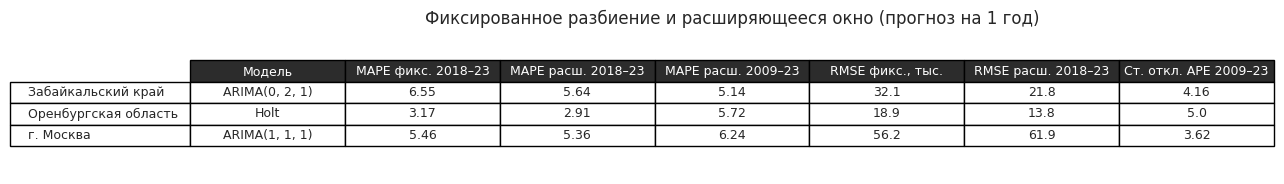

In [53]:
EXP_START = 2008

def one_step(region, name):
    fn, y, rows = model_set(region)[name], series[region], []
    for end in range(EXP_START, 2023):
        train = y[:str(end)]
        f     = fn(train, 1)
        actual = y.loc[pd.Period(end + 1, freq='Y')]
        rows.append({'year': end + 1, 'actual': actual, 'forecast': float(f.iloc[0])})
    out = pd.DataFrame(rows).set_index('year')
    out['error']     = out['actual'] - out['forecast']
    out['ape']       = (out['error'].abs() / out['actual']) * 100
    out['pct_error'] = (out['actual'] / out['forecast'] - 1) * 100
    return out

expanding = {region: one_step(region, BEST[region]) for region in SELECTED.values()}

stab_rows = []
for region in SELECTED.values():
    e   = expanding[region]
    e18 = e.loc[2018:]
    fixed = metrics[(metrics['Регион'] == region) & (metrics['Модель'] == BEST[region])].iloc[0]
    stab_rows.append({
        'Регион': region, 'Модель': BEST[region],
        'MAPE фикс. 2018–23':    fixed['MAPE, %'],
        'MAPE расш. 2018–23':    round(e18['ape'].mean(), 2),
        'MAPE расш. 2009–23':    round(e['ape'].mean(), 2),
        'RMSE фикс., тыс.':      fixed['RMSE, тыс. руб.'],
        'RMSE расш. 2018–23':    round(np.sqrt((e18['error'] ** 2).mean()) / 1e3, 1),
        'Ст. откл. APE 2009–23': round(e['ape'].std(), 2),
    })

stability = pd.DataFrame(stab_rows).set_index('Регион')
show_table(stability, 'Фиксированное разбиение и расширяющееся окно (прогноз на 1 год)', font=9)

Если обновлять модель каждый год, ошибка на 2018–2023 годах снижается: у Забайкальского края MAPE 5,64% против 6,55% при фиксированном разбиении, у Оренбургской области 2,91% против 3,17%, у Москвы 5,36% против 5,46%. Выигрыш скромный, 0,1–0,9 п.п. Это значит, что ошибка в основном возникает не от длины горизонта, а от неожиданных лет: прогноз на 1 год вперёд ошибается почти так же, как прогноз на 6 лет. У Москвы RMSE при обновлении даже выше (61,9 против 56,2 тыс. руб.): одношаговая модель сильнее ошиблась в 2021 и 2022 годах (ниже).

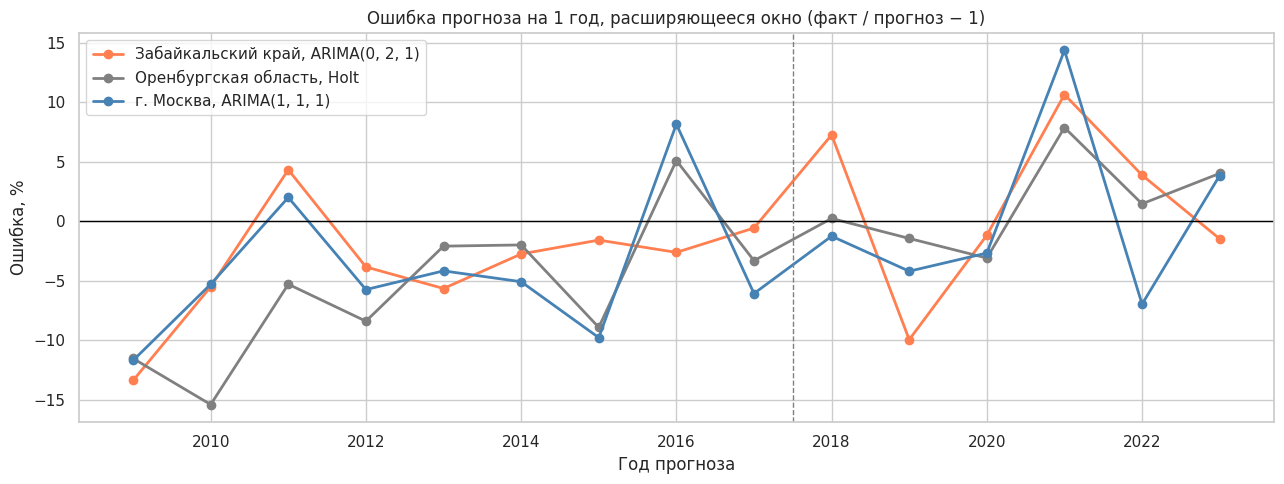

In [54]:
fig, ax = plt.subplots()
for region in SELECTED.values():
    e = expanding[region]
    ax.plot(e.index, e['pct_error'], color=COLORS[region], lw=2, marker='o', label=f'{region}, {BEST[region]}')
ax.axhline(0, color='black', lw=1)
ax.axvline(2017.5, color='gray', lw=1, ls='--')
ax.set(title='Ошибка прогноза на 1 год, расширяющееся окно (факт / прогноз − 1)', xlabel='Год прогноза', ylabel='Ошибка, %')
ax.legend(); plt.tight_layout(); plt.show()

In [55]:
for region in SELECTED.values():
    e = expanding[region]
    print(f'{region}: APE по годам')
    print(e['ape'].round(1).to_string(), end='\n\n')

Забайкальский край: APE по годам
year
2009    15.5
2010     5.8
2011     4.1
2012     4.0
2013     6.0
2014     2.8
2015     1.6
2016     2.7
2017     0.6
2018     6.8
2019    11.1
2020     1.2
2021     9.6
2022     3.7
2023     1.5

Оренбургская область: APE по годам
year
2009    13.0
2010    18.2
2011     5.6
2012     9.2
2013     2.1
2014     2.0
2015     9.8
2016     4.8
2017     3.4
2018     0.2
2019     1.5
2020     3.2
2021     7.3
2022     1.4
2023     3.9

г. Москва: APE по годам
year
2009    13.3
2010     5.6
2011     2.0
2012     6.1
2013     4.4
2014     5.4
2015    10.8
2016     7.5
2017     6.5
2018     1.3
2019     4.4
2020     2.8
2021    12.6
2022     7.5
2023     3.7



По всем 15 годам MAPE одношагового прогноза 5,14% у Забайкальского края, 5,72% у Оренбургской области и 6,24% у Москвы, стандартное отклонение годовых ошибок 3,6–5,0 п.п. Больше всего ошибки в 2009–2010 годах, когда окно короткое (9–10 точек) и пришёлся кризис.

На графике ошибок видно смещение. С 2009 по 2017 год ошибки почти всегда отрицательные: у Забайкальского края и Оренбургской области в 8 годах из 9, у Москвы в 7 из 9. Модели продолжают прошлый темп роста, а при замедлении каждый следующий год оказывается медленнее прошлого, и прогноз систематически завышен. После 2018 года знаки чередуются, а в 2021 году все три модели недооценили восстановление. Вывод об устойчивости: ошибка не растёт со временем и при обновлении данных немного снижается, но модели инерционны. Они смещены вверх в периоды замедления и вниз в годы резкого ускорения, и знак ошибки определяет экономический режим, а не случайность.

## 6. Анализ ошибок

Ошибки берутся из расширяющегося окна (раздел 5.5): там 15 одношаговых прогнозов на 2009–2023 годы, каждая ошибка показывает, насколько год оказался неожиданным для модели, которая знала всю историю до него. На фиксированном тесте всего 6 точек, и ошибки поздних лет там смешаны с накопленной ошибкой горизонта, поэтому для поиска «неожиданных» лет они подходят хуже.

Знак ошибки: положительная значит факт выше прогноза (модель недооценила рост), отрицательная значит модель переоценила.

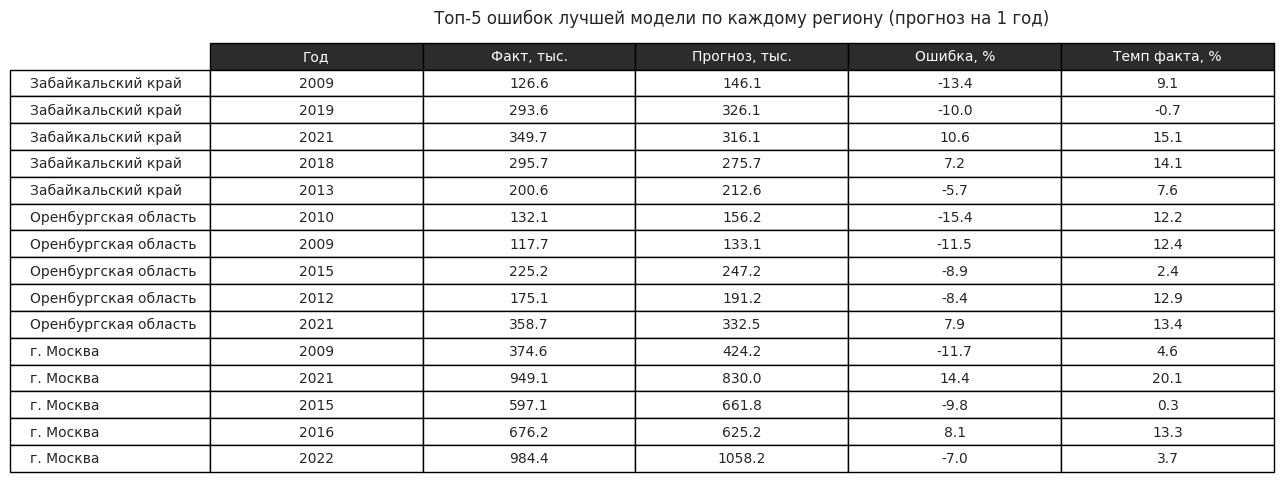

In [56]:
top_rows = []
for region in SELECTED.values():
    e = expanding[region].sort_values('ape', ascending=False).head(5)
    for year, row in e.iterrows():
        top_rows.append({'Регион': region, 'Год': year,
                         'Факт, тыс.':    round(row['actual'] / 1e3, 1),
                         'Прогноз, тыс.': round(row['forecast'] / 1e3, 1),
                         'Ошибка, %':     round(row['pct_error'], 1),
                         'Темп факта, %': round(growth.loc[year, region] * 100, 1)})

top5 = pd.DataFrame(top_rows).set_index('Регион')
show_table(top5, 'Топ-5 ошибок лучшей модели по каждому региону (прогноз на 1 год)', height=0.3)

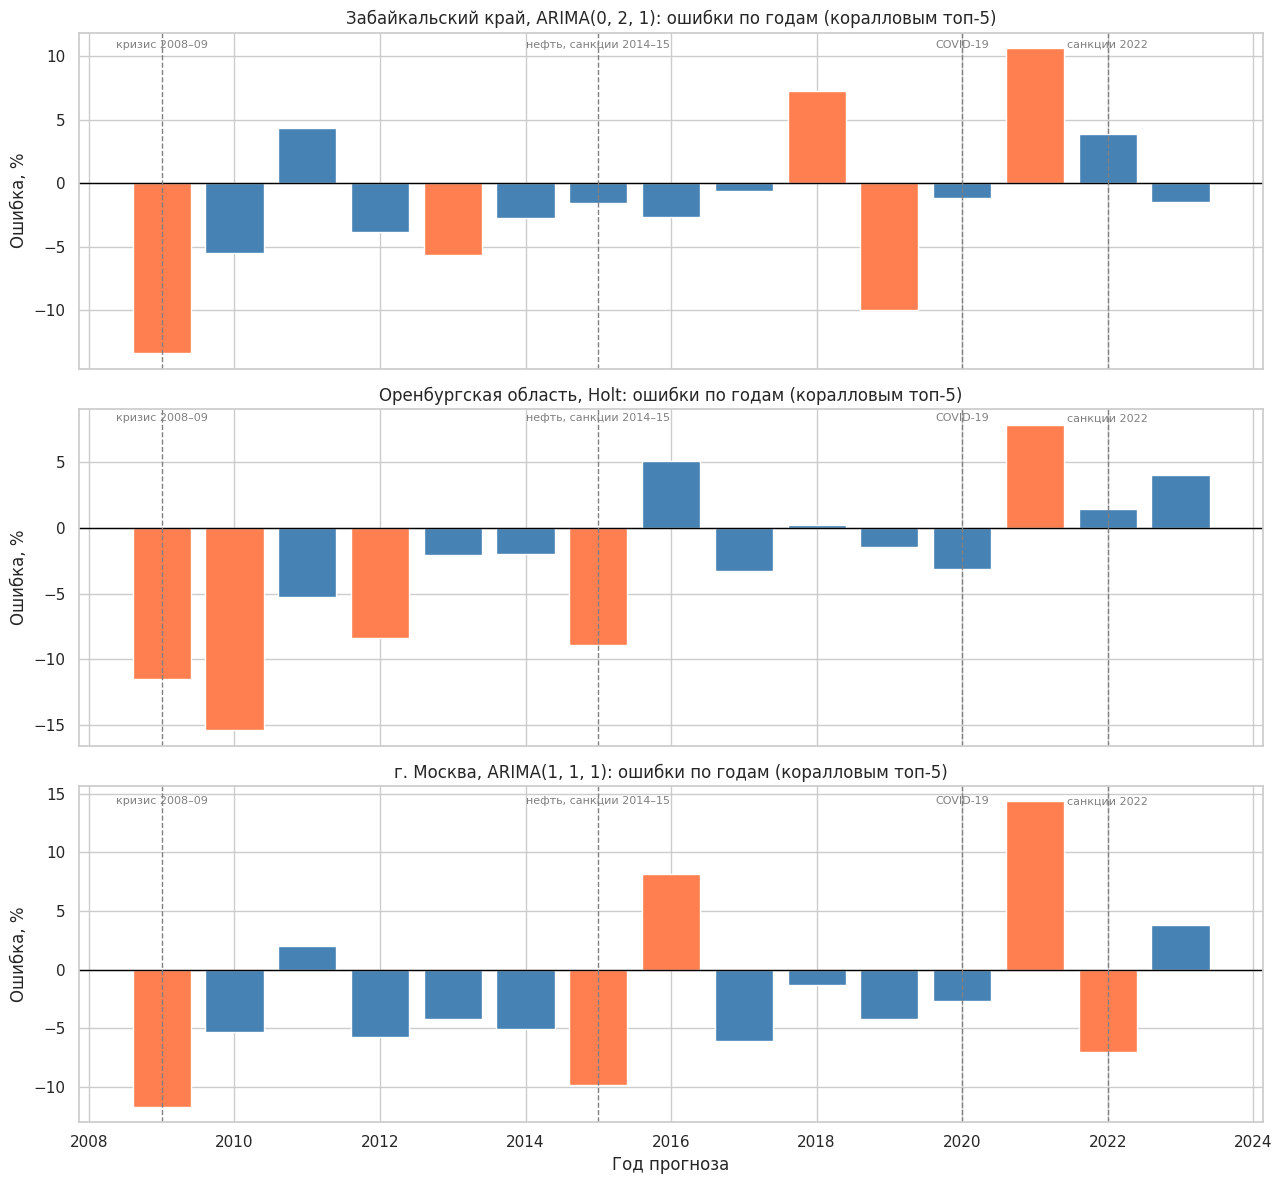

In [57]:
EVENTS = {2009: 'кризис 2008–09', 2015: 'нефть, санкции 2014–15', 2020: 'COVID-19', 2022: 'санкции 2022'}

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, region in zip(axes, SELECTED.values()):
    e   = expanding[region]
    top = e['ape'].nlargest(5).index
    ax.bar(e.index, e['pct_error'], color=['coral' if yr in top else 'steelblue' for yr in e.index])
    ax.axhline(0, color='black', lw=1)
    for yr, label in EVENTS.items():
        ax.axvline(yr, color='gray', lw=1, ls='--')
        ax.text(yr, ax.get_ylim()[1] * 0.9, label, fontsize=8, ha='center', color='gray')
    ax.set(title=f'{region}, {BEST[region]}: ошибки по годам (коралловым топ-5)', ylabel='Ошибка, %')
axes[-1].set_xlabel('Год прогноза')
plt.tight_layout(); plt.show()

Ни в одном регионе 2020 год не попал в топ-5: одношаговые ошибки 2020 года малы (от −1,2% до −3,2%). К 2020 году модели уже видели медленный 2019 год и ждали медленного роста, а номинальное потребление в 2020 году всё же выросло на 3–4%. Пандемия видна в ошибках через год: восстановление 2021 года недооценено во всех трёх регионах. Кризис 2009 года входит в топ-5 у всех трёх регионов, 2015 год у Оренбургской области и Москвы, 2022 год только у Москвы.

Гипотезы о причинах. Связь с событиями выведена по совпадению лет и знаков ошибки, данные о самих событиях в работе не использовались.

Забайкальский край, ARIMA(0, 2, 1):

1. 2009 год, −13,4%. Рост упал с 29,0% в 2008 году до 9,1%. Модель продолжила докризисный разгон. Гипотеза: кризис 2008–2009 годов ударил по добывающей экономике края через падение цен на металлы.
2. 2018 и 2019 годы, +7,2% и −10,0%. Пара ошибок противоположного знака: в 2018 году темп подскочил до 14,1% после 6,1%, модель с d = 2 приняла скачок за ускорение и ждала в 2019 году роста на 10%, а потребление снизилось на 0,7%. Общероссийского шока в 2019 году не было (медианный темп по 79 регионам 5,5%), поэтому гипотеза региональная: разовый всплеск 2018 года (например, крупный инвестиционный проект или перерасчёт данных) с возвратом к прежнему уровню. Это слабое место моделей с d = 2: они усиливают единичные скачки.
3. 2021 год, +10,6%. Восстановление после пандемии: рост 15,1% после 3,4% в 2020 году. Модель видела два медленных года подряд и не ждала отскока.
4. 2013 год, −5,7%. Рост замедлился до 7,6% после 11,9%. Это общее замедление экономики 2013 года до кризиса 2014 года, но у края оно сильнее медианного (медиана 2013 года 10,9%).

Оренбургская область, Holt:

1. 2009 и 2010 годы, −11,5% и −15,4%. Рост упал с 33,2% в 2008 году до 12,4% и 12,2%. Трендовая компонента Holt обновляется медленно, и после кризисного года модель ещё год продолжала докризисный темп: прогноз на 2010 год предполагал рост на 33%. Это главная слабость Holt: он ошибается дважды, в год шока и в год после него.
2. 2012 год, −8,4%. После отскока 2011 года (17,4%) модель ждала продолжения, а темп вернулся к 12,9%.
3. 2015 год, −8,9%. Рост всего 2,4%. Гипотеза: падение цен на нефть в 2014–2015 годах, девальвация рубля и санкции. Для нефтегазовой Оренбургской области нефтяной шок прямой.
4. 2021 год, +7,9%. Восстановление после пандемии (рост 13,4%).

Москва, ARIMA(1, 1, 1):

1. 2009 год, −11,7%. Рост упал с 18,0% до 4,6%. Гипотеза: кризис 2008–2009 годов сильнее всего ударил по финансовому сектору и услугам, на которых держатся доходы столицы.
2. 2015 и 2016 годы, −9,8% и +8,1%. Рост 0,3% в 2015 году и 13,3% в 2016 году. Гипотеза: девальвация 2014–2015 годов, московское потребление сильнее завязано на импорт. Затем быстрый отскок, который модель с MA-компонентой недооценила, потому что приняла провал за устойчивый.
3. 2021 год, +14,4%, самая большая ошибка Москвы. Рост 20,1% после 3,1%. Гипотеза: отложенный спрос после ограничений 2020 года, которые в Москве были строже, чем в большинстве регионов.
4. 2022 год, −7,0%. Рост 3,7% после 20,1%. Две гипотезы, которые здесь действуют вместе: модель продолжила всплеск 2021 года, и санкции 2022 года с уходом иностранных брендов, торговля и услуги которых сосредоточены в Москве.

Общий вывод: модели ошибаются не случайно, а в годы смены режима. В топ-5 ошибки шоковых лет (2009, 2015, 2019 у Забайкальского края, 2022) все отрицательные, модель переоценивает рост. Ошибки лет отскока (2016 у Москвы, 2021 у всех трёх регионов) все положительные. Одномерная модель видит только собственную историю ряда и узнаёт о шоке на год позже.

## 7. Рекомендации по регионам

Рекомендации адресованы тем, кто планирует по этим прогнозам: региональным финансовым органам (социальные выплаты, налоговые поступления от потребления) и бизнесу, который планирует спрос. Все суммы номинальные, в рублях на душу населения в текущих ценах.

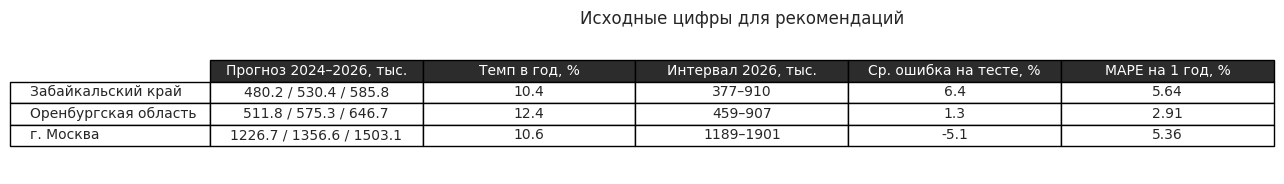

In [58]:
reco_base = {}
for region in SELECTED.values():
    f = future[region]
    reco_base[region] = {
        'Прогноз 2024–2026, тыс.':  ' / '.join(f'{v / 1e3:.1f}' for v in f['forecast']),
        'Темп в год, %':            round(((f['forecast'].iloc[-1] / series[region].iloc[-1]) ** (1 / H_FUTURE) - 1) * 100, 1),
        'Интервал 2026, тыс.':      f"{f['lower'].iloc[-1] / 1e3:.0f}–{f['upper'].iloc[-1] / 1e3:.0f}",
        'Ср. ошибка на тесте, %':   round(test_err.loc[:, region].mean(), 1),
        'MAPE на 1 год, %':         stability.loc[region, 'MAPE расш. 2018–23'],
    }
reco_base = pd.DataFrame(reco_base).T
show_table(reco_base, 'Исходные цифры для рекомендаций')

In [59]:
oren_mid    = growth.loc[2015:2020, 'Оренбургская область'].mean()
oren_mid26  = series['Оренбургская область'].iloc[-1] * (1 + oren_mid) ** H_FUTURE
oren_shock  = expanding['Оренбургская область'].loc[[2009, 2010, 2015], 'pct_error'].mean()
msk_bias    = test_err.loc[:, 'г. Москва'].mean()
msk_shock   = expanding['г. Москва'].loc[[2009, 2015, 2022], 'pct_error'].mean()

print(f'Оренбургская область: средний темп 2015–2020 {oren_mid * 100:.1f}%, уровень 2026 при таком темпе {oren_mid26 / 1e3:.1f} тыс.')
print(f'Оренбургская область: средняя ошибка Holt в шоковые годы 2009, 2010, 2015: {oren_shock:.1f}%,',
      f'прогноз 2025 в шоковом сценарии {future["Оренбургская область"]["forecast"].iloc[1] * (1 + oren_shock / 100) / 1e3:.1f} тыс.')
print(f'Москва: средняя ошибка на тесте {msk_bias:.1f}%, прогноз с поправкой:',
      ' / '.join(f'{v * (1 + msk_bias / 100) / 1e3:.1f}' for v in future['г. Москва']['forecast']))
print(f'Москва: средняя ошибка в шоковые годы 2009, 2015, 2022: {msk_shock:.1f}%')

Оренбургская область: средний темп 2015–2020 6.3%, уровень 2026 при таком темпе 546.8 тыс.
Оренбургская область: средняя ошибка Holt в шоковые годы 2009, 2010, 2015: -12.0%, прогноз 2025 в шоковом сценарии 506.5 тыс.
Москва: средняя ошибка на тесте -5.1%, прогноз с поправкой: 1164.5 / 1287.9 / 1427.0
Москва: средняя ошибка в шоковые годы 2009, 2015, 2022: -9.5%


### Забайкальский край

1. Планировать по нижней части интервала, а не по точечному прогнозу. Точечный прогноз на 2026 год 585,8 тыс. руб. (+10,4% в год), но 95% интервал 377–910 тыс. руб. самый широкий среди трёх регионов, и его нижняя граница ниже фактического уровня 2023 года (434,8 тыс. руб.). Надёжен только первый год: на 2024 год прогноз 480,2 тыс. руб., интервал 407–567 тыс. руб. Обязательства, которые зависят от потребления, на 2025–2026 годы стоит закладывать по сценарию без роста к 2023 году, как в 2019 году, когда потребление снизилось на 0,7%.
2. Не продолжать разовые скачки. Модель ARIMA(0, 2, 1) продолжает ускорение: после роста на 14,1% в 2018 году она ждала ещё 10% в 2019 году и ошиблась на 10,0%. Если в каком-то году рост окажется выше примерно 14%, прогноз на следующий год лучше брать как среднее ARIMA(0, 2, 1) и Holt: на тесте их точность почти одинакова (MAPE 6,55% и 6,86%), а Holt на скачки реагирует слабее.
3. Учесть отставание от типичного региона. По прогнозу край растёт на 10,4% в год, Оренбургская область, эталон кластера 1, на 12,4%. Отношение уровня края к оренбургскому снизится с 95% в 2023 году до 91% в 2026 году. Если для региона важно не отставать от типичной траектории, это отставание на 4 п.п. за три года стоит сразу закладывать в программы социально-экономического развития, а не узнавать о нём из факта.

### Оренбургская область

1. Использовать Holt как основной инструмент планирования на год вперёд. Это самый точный прогноз в работе: MAPE 3,17% на тесте и 2,91% при ежегодном обновлении. На 2024 год прогноз 511,8 тыс. руб., с учётом типичной ошибки около 3% рабочий диапазон 496–527 тыс. руб., он заметно уже статистического интервала 451–574 тыс. руб.
2. Считать прогноз на 2025–2026 годы оптимистичным сценарием. Темп 12,4% в год Holt взял из трёх последних лет (13,4%, 10,9%, 14,5%). Если темп вернётся к среднему 2015–2020 годов (6,3%), уровень 2026 года будет около 547 тыс. руб., на 15% ниже прогноза 646,7 тыс. руб. Диапазон 547–647 тыс. руб. на 2026 год честнее точечной цифры.
3. Иметь шоковый сценарий. В годы шоков (2009, 2010, 2015) Holt переоценивал потребление области в среднем на 12,0%, причём ошибался два года подряд, потому что тренд модели обновляется медленно. В шоковый год прогноз нужно снижать примерно на 12%: для 2025 года это 506,5 тыс. руб. вместо 575,3 тыс. руб. Следующий за шоком год тоже нужно пересматривать вручную, модель сама этого не сделает.

### Москва

1. Вносить поправку на смещение. ARIMA(1, 1, 1) переоценивала Москву во все шесть тестовых лет, в среднем на 5,1%. С поправкой прогноз на 2024–2026 годы равен 1164,5, 1287,9 и 1427,0 тыс. руб. вместо 1226,7, 1356,6 и 1503,1 тыс. руб. Поправка уместна, пока смещение сохраняется. Если в 2024 году ошибка сменит знак, поправку надо убрать.
2. Держать стресс-сценарий на внешний шок. У Москвы три из пяти главных ошибок пришлись на внешние шоки: 2009 год (−11,7%), 2015 год (−9,8%) и 2022 год (−7,0%). В среднем модель переоценивала потребление на 9,5%. Для планирования доходов, которые зависят от потребления, нужен сценарий −10% к прогнозу на год шока.
3. Не урезать план на год после шока. После провалов Москва быстро восстанавливалась: в 2016 году рост 13,3% после 0,3%, в 2021 году 20,1% после 3,1%, и модель оба раза недооценила факт (+8,1% и +14,4%). Если 2024–2026 годы начнутся со спада, план на следующий год не стоит снижать вслед за моделью, восстановление в Москве исторически наступало в течение одного года.

## 8. Выводы

Кластеризация по пяти признакам динамики разделила 79 субъектов на три группы (k-means, k = 3, силуэт 0,264). Кластер 0 (8 регионов, например Забайкальский край, Кемеровская область, Дагестан, Чукотка) растёт быстрее всех (16,2% в год), но с откатами: волатильность темпа 11,1 п.п. и номинальное падение хотя бы в одном году у 7 из 8 регионов. Кластер 1 (55 регионов) растёт ровно и держится у медианы. Кластер 2 (16 регионов, Москва, северные и ресурсные регионы) на 41% выше медианы по уровню, растёт медленнее всех (14,2%), и его сближение с остальными регионами остановилось в 2015 году. Силуэт невысокий: регионы образуют непрерывное облако, и кластеры описывают зоны этого облака, а не изолированные группы.

Лучшие модели различаются по типу региона:

1. Кластер 0, Забайкальский край: ARIMA(0, 2, 1), MAPE 6,55%. Holt почти так же точен (6,86%).
2. Кластер 1, Оренбургская область: Holt, MAPE 3,17%.
3. Кластер 2, Москва: ARIMA(1, 1, 1) со сносом, RMSE 56,2 тыс. руб. (MAPE 5,46%). Holt чуть хуже по RMSE, но лучше по MAPE (5,03%).

Общая закономерность: в регионах, где темп роста за период сильно упал (кластеры 0 и 1), выигрывают модели, которые продолжают последний темп (Holt и ARIMA с d = 2). Модель с постоянным средним темпом, ARIMA(1, 1, 0) со сносом, на этих рядах проваливается хуже наивного сноса (MAPE 19,7–23,3%). Там, где темп замедлялся мягко (Москва), модель с d = 1 работает. Все лучшие модели обгоняют оба наивных прогноза, у сноса они выигрывают от 1,8 до 5,6 п.п. MAPE.

На точность влияют три фактора. Первый это режим экономики: в 2009–2017 годах ошибки почти всегда отрицательные (модели продолжают прошлый, более высокий темп), а в годы отскока положительные. Второй это шоки: наибольшие ошибки пришлись на 2009, 2015, 2021 и 2022 годы, а также на региональные скачки (Забайкальский край, 2018–2019 годы). Третий это волатильность ряда: самый шумный регион (Забайкальский край) имеет и самый широкий интервал прогноза. Обновление модели каждый год снижает ошибку лишь на 0,1–0,9 п.п.: ошибка определяется неожиданностью года, а не длиной горизонта.

Ограничения:

1. Данные номинальные. Модели прогнозируют сумму роста физического потребления и инфляции и не отделяют одно от другого. Прогноз в 10–12% в год нельзя читать как рост уровня жизни.
2. Ряды короткие: 24 годовые точки, 18 в обучении. Тест ADF, ACF и PACF на такой длине имеют низкую мощность, AIC близких моделей различается меньше чем на 1,5 единицы. Выводы о порядках моделей предварительные.
3. Модели одномерные. Они не знают о ценах на нефть, курсе рубля, инфляции, доходах и трансфертах и узнают о шоке только через год, по его следу в ряде.
4. Каждый кластер представлен одним регионом. Выводы о том, какая модель лучше для группы, проверены на одном представителе и могут не перенестись на другие регионы кластера, особенно на неоднородный кластер 0.
5. Есть вмешательства в данные: значение Красноярского края за 2004 год заменено, данные Забайкальского края за годы до 2008 года, вероятно, пересчитаны на новые границы. Интервалы прогноза предполагают, что будущие шоки будут не сильнее прошлых.

Что можно улучшить:

1. Дефлировать ряды региональными индексами потребительских цен и прогнозировать реальное потребление отдельно от инфляции.
2. Добавить внешние переменные (ARIMAX или регрессия с ошибками ARIMA): инфляцию, цену нефти, реальные доходы.
3. Обучать одну модель сразу на всех 79 регионах (панельная или глобальная модель темпов роста с лагами). Короткие ряды отдельных регионов дополнят друг друга, и выводы можно будет проверить по всему кластеру, а не по одному представителю.
4. Проверить Holt с затухающим трендом и комбинацию Holt и ARIMA. Затухание отвечает на главную проблему, системное замедление темпа. Комбинация сглаживает ошибки отдельных моделей в годы скачков.
5. Перейти на квартальные данные, если они доступны: в 4 раза больше точек сделают тесты и подбор порядка надёжнее.